# **Poverty and Inequality Analysis Using World Bank Data**

**Dataset:** `PovStatsEXCEL.xlsx`  
**Focus:** Poverty and income inequality trends in India  
**Tools:** Python, Pandas, Matplotlib, Excel

> This notebook analyses selected poverty and inequality indicators for India using the World Bank dataset. The dataset contains country-level indicators observed over multiple years. Many observations are missing because household-survey indicators are not measured every year; therefore, the analysis uses the years for which values are available rather than treating missing values as zero.

**Statistical techniques included (full syllabus coverage):** histograms, stem plots, scatter plots, populations and samples; mean, median, mode, variance, standard deviation, percentiles and box plots; least-squares curve fitting (straight line and parabola), correlation, regression and rank correlation (Pearson and Spearman); sampling distributions, standard error, confidence intervals, the Central Limit Theorem, Type-I / Type-II errors, one- and two-tailed tests and Z-tests; Student's t-tests and chi-square tests.

## 1. Introduction

Poverty and income inequality are important measures of a country's economic and social development. Poverty indicators show the proportion of people living below a specified poverty line, while inequality indicators describe how income or consumption is distributed among the population.

This project uses the World Bank Poverty and Inequality dataset to examine selected indicators for India. The analysis focuses on:

- Poverty headcount ratio at **$3.20 a day (2011 PPP)**.
- Poverty headcount ratio at **national poverty lines**.
- **Gini index**, which measures income or consumption inequality.
- Income share held by the **lowest 20%** of the population.

The purpose is to summarise the available observations, visualise changes over time, and interpret the trends. The analysis is descriptive and does not establish the causes of changes in poverty or inequality.

## 2. Problem Statement

Poverty and inequality can change over time due to economic, social, demographic and policy-related factors. However, understanding these changes requires examining reliable data across different years.

The problem addressed in this project is to understand what the available World Bank data indicate about poverty and income inequality in India.

The analysis attempts to answer the following questions:

1. How has the poverty headcount ratio at $3.20 a day (2011 PPP) changed across the available survey years?
2. How has the poverty headcount ratio measured using India's national poverty line changed?
3. What pattern is visible in the Gini index over the available years?
4. How has the income share held by the lowest 20% changed?
5. What do these indicators collectively suggest about poverty reduction and income distribution?
6. Using all countries in the workbook, are the inequality patterns observed in India typical, and do regions or income groups differ significantly in inequality (statistical inference)?

**Scope and limitations:** The dataset contains many countries, indicators and years, but several values are missing. Poverty and inequality observations are often based on household surveys and are not necessarily available annually. The analysis therefore uses only available observations for India. The selected indicators use different definitions and poverty thresholds, so their values should not be directly treated as interchangeable.

## 3. Method

The following steps are used:

1. **Load the dataset:** Read the `Data` worksheet from the Excel workbook using Pandas.
2. **Inspect the structure:** Check the number of rows and columns, column names, data types and missing values.
3. **Prepare the data:** Identify year columns, select India's records, and convert the wide year-based format into a long format with `Year` and `Value` columns.
4. **Select indicators:** Extract the four poverty and inequality indicators listed in the introduction.
5. **Summarise:** Display available observations and calculate the first-to-last change for each indicator.
6. **Visualise:** Create line charts to show the available observations over time.
7. **Describe the data (Modules 1–2):** histograms, stem plots, scatter plots, measures of centre and spread, percentiles and box plots.
8. **Model relationships (Module 3):** least-squares line and parabola, correlation, regression and rank correlation.
9. **Draw inferences (Modules 4–5):** sampling distributions, confidence intervals, Z-tests, t-tests and chi-square tests using the cross-country data.
10. **Interpret:** Describe the direction of change while considering missing years and differences in indicator definitions.

The notebook does not fill missing observations with zero or invent values for years that are not present.

### 3.1 About Dataset

World Bank poverty and inequality data. Two views of the data are used:

- **India time series** – the few survey years in which India's indicators were measured (small sample, `n` = 4 to 7).
- **Cross-country population** – the latest available observation for each of the ~190 countries in the workbook (large sample, `n` ≈ 160–180). This is used wherever a larger sample is needed (sampling distributions, Z-tests, χ² tests, etc.).

| Module | Syllabus topics | Where in this notebook |
|---|---|---|
| 1 | Basic visualization, histograms, stem plots, scatter plots, populations and samples | Section 4 |
| 2 | Mean, median, mode, variance, standard deviation, percentiles, box plots | Section 5 |
| 3 | Curve fitting by least squares (straight line, parabola), correlation, regression, rank correlation (Pearson, Spearman) | Section 6 |
| 4 | Sampling distribution, standard error, confidence interval, Central Limit Theorem, Type-I / Type-II errors, level of significance, one- and two-tailed tests, Z-test (mean, proportion) | Section 7 |
| 5 | Null / alternate hypothesis, Student's t-test (single mean, difference of two means), χ² test (goodness of fit, independence) | Section 8 |

In [ ]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the Excel workbook.
# Keep PovStatsEXCEL.xlsx in the same folder as this notebook.
file_path = "PovStatsEXCEL.xlsx"

# If running in Google Colab and the file is not present, upload it.
from pathlib import Path
if not Path(file_path).exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            "Place PovStatsEXCEL.xlsx in the notebook folder and run this cell again."
        )

# Load the main data worksheet
data = pd.read_excel(file_path, sheet_name="Data")

print("Dataset loaded successfully.")
print("Shape:", data.shape)
display(data.head())

Dataset loaded successfully.
Shape: (13068, 51)


,Country Name,Country Code,Indicator Name,Indicator Code,1974,1975,1976,1977,1978,1979,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.SPR.PC40.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.SPR.PT10.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.SPR.PT60.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.SPR.PCAP.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.POV.XPND.MD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Inspect dataset structure and data quality
print("Column names:")
print(data.columns.tolist())

print("\nDataset information:")
data.info()

print("\nNumber of missing values in the first columns:")
display(data.isnull().sum().head(10))

print("\nNumber of countries:", data["Country Name"].nunique())
print("Number of indicators:", data["Indicator Name"].nunique())

# Identify columns whose names are years
year_columns = [col for col in data.columns if str(col).isdigit()]
print("Year range in the dataset:", year_columns[0], "to", year_columns[-1])
print("Number of year columns:", len(year_columns))

Column names:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 13068 entries, 0 to 13067
Data columns (total 51 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    13068 non-null  str    
 1   Country Code    13068 non-null  str    
 2   Indicator Name  13068 non-null  str    
 3   Indicator Code  13068 non-null  str    
 4   1974            223 non-null    float64
 5   1975            223 non-null    float64
 6   1976            189 non-null    float64
 7   1977       

Country Name          0
Country Code          0
Indicator Name        0
Indicator Code        0
1974              12845
1975              12845
1976              12879
1977              12870
1978              12862
1979              12794
dtype: int64


Number of countries: 198
Number of indicators: 66
Year range in the dataset: 1974 to 2020
Number of year columns: 47


In [ ]:
# Select the four indicators for India
selected_indicators = [
    "Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population)",
    "Poverty headcount ratio at national poverty lines (% of population)",
    "Gini index (World Bank estimate)",
    "Income share held by lowest 20%"
]

india = data[data["Country Name"] == "India"].copy()

# Convert year columns from wide format to long format
india_long = india.melt(
    id_vars=["Country Name", "Country Code", "Indicator Name", "Indicator Code"],
    value_vars=year_columns,
    var_name="Year",
    value_name="Value"
)

india_long["Year"] = pd.to_numeric(india_long["Year"], errors="coerce")
india_long["Value"] = pd.to_numeric(india_long["Value"], errors="coerce")

# Keep only the selected indicators and available observations
analysis_data = india_long[
    india_long["Indicator Name"].isin(selected_indicators)
].dropna(subset=["Value"]).sort_values(["Indicator Name", "Year"])

print("Available observations for India:")
display(analysis_data[["Indicator Name", "Year", "Value"]].reset_index(drop=True))

Available observations for India:


,Indicator Name,Year,Value
0,Gini index (World Bank estimate),1983,32.1
1,Gini index (World Bank estimate),1987,32.6
2,Gini index (World Bank estimate),1993,31.7
3,Gini index (World Bank estimate),2004,34.4
4,Gini index (World Bank estimate),2009,35.4
5,Gini index (World Bank estimate),2011,35.7
6,Income share held by lowest 20%,1983,8.5
7,Income share held by lowest 20%,1987,8.7
8,Income share held by lowest 20%,1993,8.9
9,Income share held by lowest 20%,2004,8.5


In [ ]:
# Create a summary table for each selected indicator
summary_rows = []

for indicator in selected_indicators:
    subset = analysis_data[analysis_data["Indicator Name"] == indicator].sort_values("Year")

    if not subset.empty:
        first = subset.iloc[0]
        last = subset.iloc[-1]
        summary_rows.append({
            "Indicator": indicator,
            "First available year": int(first["Year"]),
            "First value": first["Value"],
            "Latest available year": int(last["Year"]),
            "Latest value": last["Value"],
            "Change": last["Value"] - first["Value"],
            "Number of observations": len(subset)
        })

summary = pd.DataFrame(summary_rows)
display(summary.round(2))

,Indicator,First available year,First value,Latest available year,Latest value,Change,Number of observations
0,Poverty headcount ratio at $3.20 a day (2011 P...,1977,88.7,2011,61.7,-27.0,7
1,Poverty headcount ratio at national poverty li...,1993,45.3,2011,21.9,-23.4,4
2,Gini index (World Bank estimate),1983,32.1,2011,35.7,3.6,6
3,Income share held by lowest 20%,1983,8.5,2011,8.1,-0.4,6


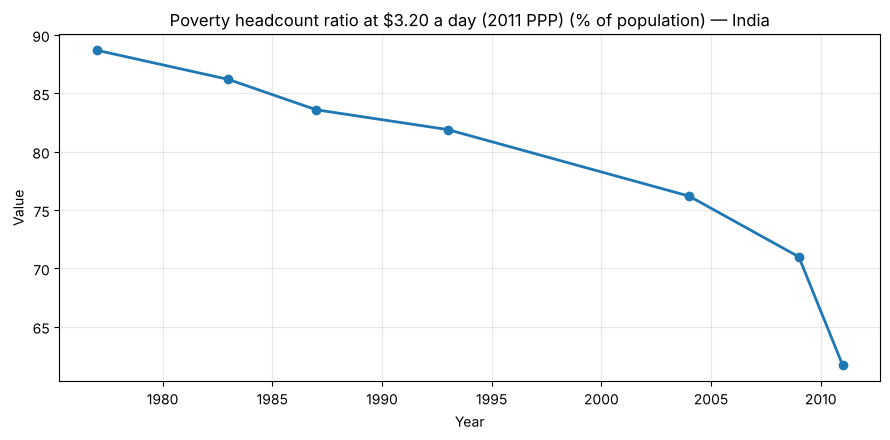

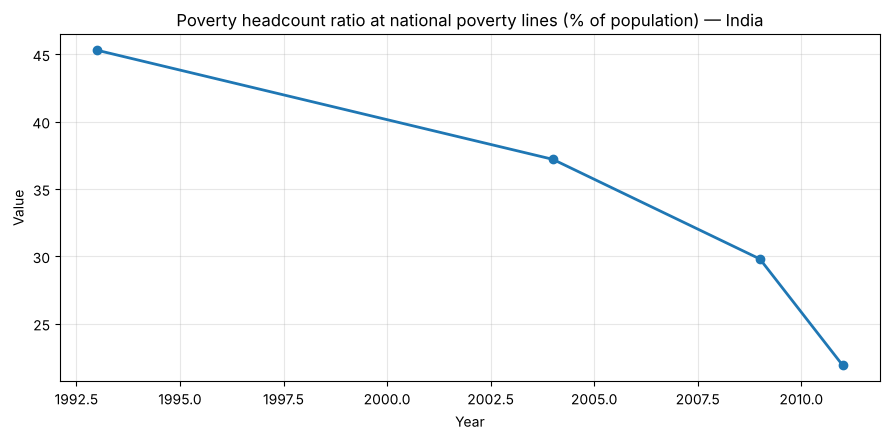

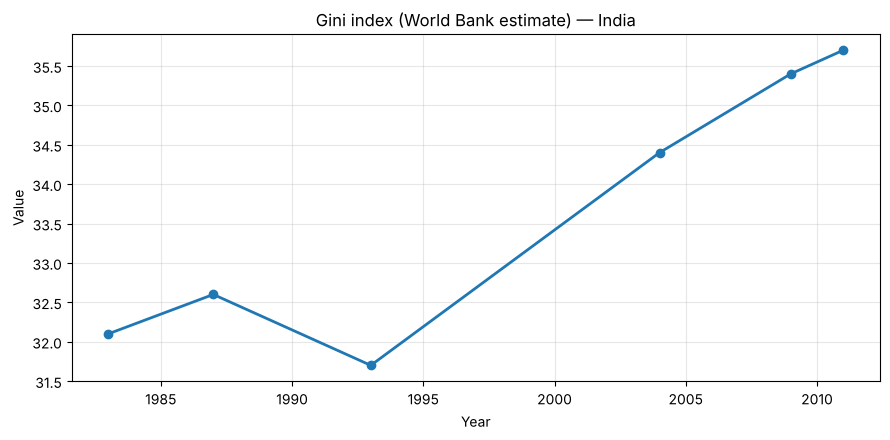

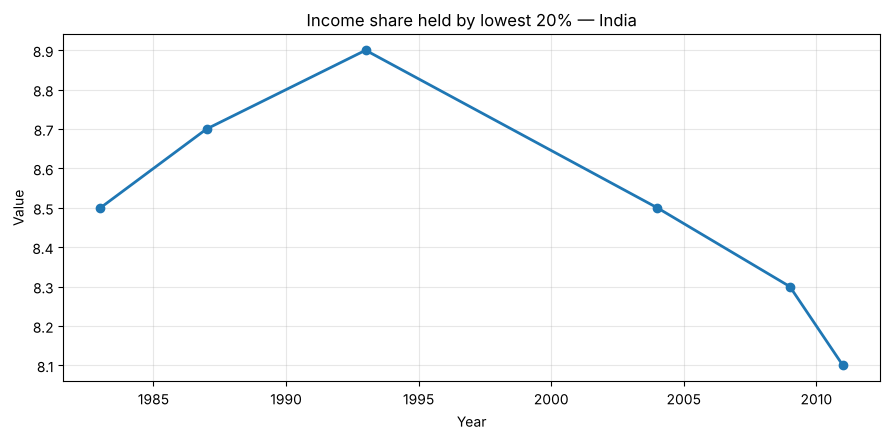

In [ ]:
# Visualise each indicator separately
for indicator in selected_indicators:
    subset = analysis_data[analysis_data["Indicator Name"] == indicator].sort_values("Year")

    if not subset.empty:
        plt.figure(figsize=(9, 4.5))
        plt.plot(subset["Year"], subset["Value"], marker="o", linewidth=2)
        plt.title(indicator + " — India")
        plt.xlabel("Year")
        plt.ylabel("Value")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

### Cross-country dataset (population used for sampling and hypothesis testing)

For every country listed in the `Country` sheet, the **latest available non-missing value** of each indicator is extracted. Regional / income-group aggregates (e.g. "World", "South Asia") are excluded so that each row is a single country. Region and income group are attached from the `Country` sheet.

> **Caveat:** the "latest observation" is from different survey years for different countries, so this is a cross-section of *latest available* data, not a single common year.

In [ ]:
from scipy import stats
import warnings
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

# Country metadata (region and income group) from the "Country" sheet
country_info = pd.read_excel(file_path, sheet_name="Country")[
    ["Country Code", "Short Name", "Region", "Income Group"]
]
valid_codes = set(country_info["Country Code"])      # real countries only (no aggregates)

cross_indicators = {
    "Gini": "Gini index (World Bank estimate)",
    "Poverty $1.90": "Poverty headcount ratio at $1.90 a day (2011 PPP) (% of population)",
    "Poverty $3.20": "Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population)",
    "Lowest 20% share": "Income share held by lowest 20%",
    "Highest 20% share": "Income share held by highest 20%",
}

def latest_observation(indicator_name):
    """Latest non-missing value (and its year) for every country."""
    sub = (data[(data["Indicator Name"] == indicator_name) &
                (data["Country Code"].isin(valid_codes))]
           .set_index("Country Code")[year_columns])
    values = sub.apply(lambda r: r.dropna().iloc[-1] if r.notna().any() else np.nan, axis=1)
    years = sub.apply(lambda r: r.dropna().index[-1] if r.notna().any() else np.nan, axis=1)
    return values, years

cross = country_info.set_index("Country Code").copy()
for label, name in cross_indicators.items():
    cross[label], yrs = latest_observation(name)
    if label == "Gini":
        cross["Gini year"] = yrs

# Inequality category (used later for chi-square tests)
cross["Inequality level"] = pd.cut(
    cross["Gini"], bins=[0, 30, 40, 100],
    labels=["Low (Gini ≤ 30)", "Moderate (30 < Gini ≤ 40)", "High (Gini > 40)"]
)

print("Countries in cross-country table:", len(cross))
print("Non-missing values per indicator:")
display(cross[list(cross_indicators)].notna().sum().to_frame("Countries with data"))
display(cross[list(cross_indicators)].describe().round(2))

# India's indicators arranged by survey year (also rebuilt later in Section 6.2)
indicator_wide = pd.DataFrame({
    ind: analysis_data[analysis_data["Indicator Name"] == ind].set_index("Year")["Value"]
    for ind in selected_indicators
})

# Short handles used throughout the notebook
gini_pop = cross["Gini"].dropna()
pov320_pop = cross["Poverty $3.20"].dropna()
india_cross = cross.loc["IND"]
print("\nIndia (latest observation):")
display(india_cross.to_frame("India").T)

Countries in cross-country table: 189
Non-missing values per indicator:


,Countries with data
Gini,164
Poverty $1.90,178
Poverty $3.20,178
Lowest 20% share,163
Highest 20% share,164


,Gini,Poverty $1.90,Poverty $3.20,Lowest 20% share,Highest 20% share
count,164.00,178.00,178.00,163.00,164.00
mean,38.27,14.13,26.36,6.62,45.34
std,7.92,20.27,29.46,1.82,6.51
min,24.60,0.00,0.00,2.40,33.80
25%,32.78,0.40,1.12,5.35,40.80
50%,37.05,2.95,10.20,6.80,44.40
75%,42.65,21.78,51.10,7.85,48.62
max,63.00,78.80,91.60,10.80,68.20



India (latest observation):


,Short Name,Region,Income Group,Gini,Gini year,Poverty $1.90,Poverty $3.20,Lowest 20% share,Highest 20% share,Inequality level
India,India,South Asia,Lower middle income,35.7,2011,22.5,61.7,8.1,44.4,Moderate (30 < Gini ≤ 40)


## 4. Basic Visualization Techniques; Populations and Samples

Visualization is the first step of any statistical analysis. It reveals the **shape**, **centre**, **spread** and **unusual values** of the data before any formula is applied.

### 4.1 Histograms

A histogram groups numerical data into class intervals (bins) and draws bars whose heights equal the frequency (or relative frequency) in each bin. The number of classes can be guided by **Sturges' rule**:

$$
\boxed{k = 1 + 3.322\,\log_{10} N}
$$

where $N$ is the number of observations and $k$ is the suggested number of classes. The class width is $h = \dfrac{X_{\max} - X_{\min}}{k}$.

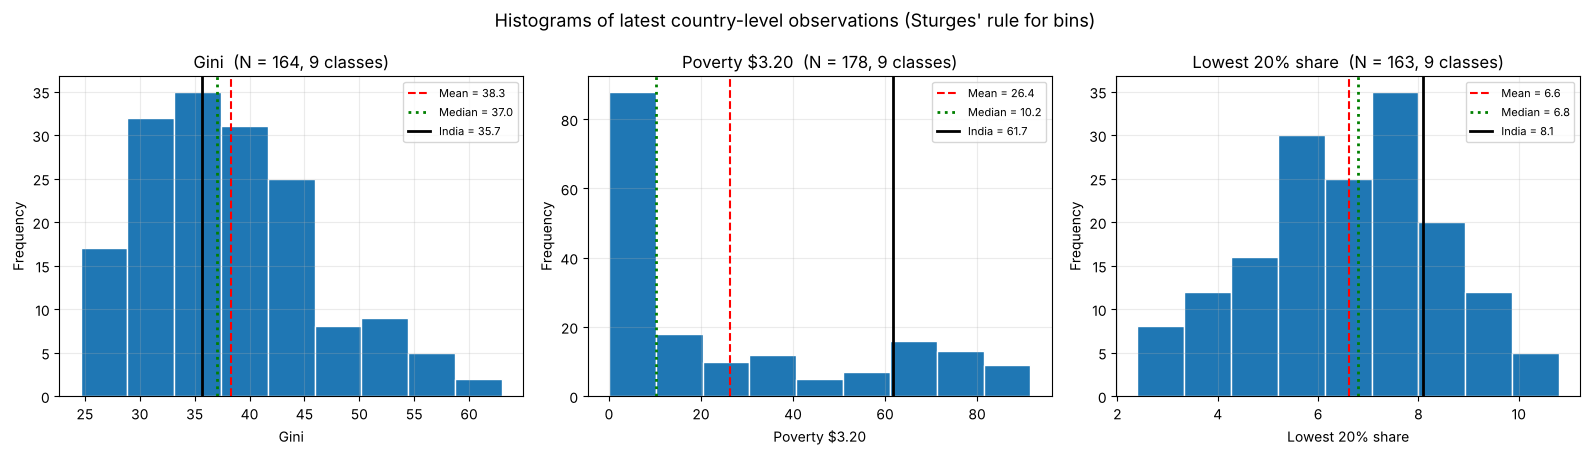

In [ ]:
# Histograms of the cross-country distributions (latest observation per country)
hist_vars = ["Gini", "Poverty $3.20", "Lowest 20% share"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

for ax, var in zip(axes, hist_vars):
    vals = cross[var].dropna()
    k = int(np.ceil(1 + 3.322 * np.log10(len(vals))))          # Sturges' rule
    ax.hist(vals, bins=k, edgecolor="white")
    ax.axvline(vals.mean(), color="red", linestyle="--", label=f"Mean = {vals.mean():.1f}")
    ax.axvline(vals.median(), color="green", linestyle=":", linewidth=2, label=f"Median = {vals.median():.1f}")
    ind_val = india_cross[var]
    ax.axvline(ind_val, color="black", linewidth=2, label=f"India = {ind_val:.1f}")
    ax.set_title(f"{var}  (N = {len(vals)}, {k} classes)")
    ax.set_xlabel(var); ax.set_ylabel("Frequency"); ax.legend(fontsize=8)

fig.suptitle("Histograms of latest country-level observations (Sturges' rule for bins)", fontsize=13)
plt.tight_layout(); plt.show()

### 4.2 Stem-and-Leaf and Stem Plots

A **stem-and-leaf plot** splits each observation into a *stem* (leading digits) and a *leaf* (last digit). It keeps the original data values visible while showing the shape of the distribution – like a histogram turned sideways.

A **stem (lollipop) plot** draws a vertical line from the baseline to each data point and is useful for discrete time-indexed observations such as India's survey years.

Stem-and-leaf: India's Gini index (6 survey years)
31 | 7
32 | 16
33 | 
34 | 4
35 | 47
Key: 32 | 1 means 32.1

Stem-and-leaf: Gini index of all countries (rounded to integer, split stems)
2 | 
  | 555566777788888999
3 | 00000000111112222222333333333333344444444
  | 5555555555666666666777777888888889999999
4 | 00000011111122222222222333334444
  | 5555556666788889
5 | 0011113334
  | 566789
6 | 3
  | 
Key: 3 | 8 means Gini ≈ 38  (each stem has two lines: leaves 0–4 and 5–9)


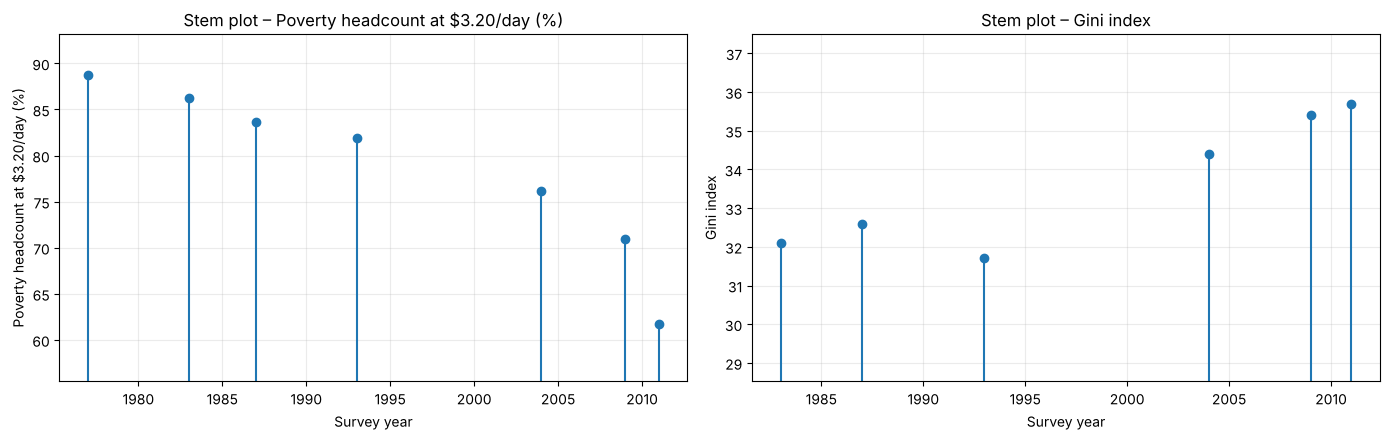

In [ ]:
def stem_and_leaf(values, mult=1, split=False, key=""):
    """Print a stem-and-leaf plot.
    values : numeric data; mult : factor that makes the last digit the leaf
    (mult=10 for 32.1 -> stem 32, leaf 1; mult=1 for 38 -> stem 3, leaf 8)
    split  : use two lines per stem (leaves 0-4 and 5-9) for long data sets."""
    scaled = sorted(int(round(v * mult)) for v in pd.Series(values).dropna())
    stems = {}
    for s in scaled:
        stems.setdefault(s // 10, []).append(s % 10)
    lo, hi = min(stems), max(stems)
    w = len(str(hi))
    for st in range(lo, hi + 1):
        leaves = stems.get(st, [])
        if split:
            print(f"{st:>{w}} | {''.join(str(l) for l in leaves if l < 5)}")
            print(f"{'':>{w}} | {''.join(str(l) for l in leaves if l >= 5)}")
        else:
            print(f"{st:>{w}} | {''.join(str(l) for l in leaves)}")
    print(key)

print("Stem-and-leaf: India's Gini index (6 survey years)")
stem_and_leaf(indicator_wide[selected_indicators[2]], mult=10, key="Key: 32 | 1 means 32.1")

print("\nStem-and-leaf: Gini index of all countries (rounded to integer, split stems)")
stem_and_leaf(gini_pop, mult=1, split=True, key="Key: 3 | 8 means Gini ≈ 38  (each stem has two lines: leaves 0–4 and 5–9)")

# Stem (lollipop) plots for India's time series
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, ind, lab in zip(axes, [selected_indicators[0], selected_indicators[2]],
                        ["Poverty headcount at $3.20/day (%)", "Gini index"]):
    s = indicator_wide[ind].dropna()
    ax.stem(s.index, s.values)
    ax.set_title(f"Stem plot – {lab}")
    ax.set_xlabel("Survey year"); ax.set_ylabel(lab)
    ax.set_ylim(s.min() * 0.9, s.max() * 1.05)
plt.tight_layout(); plt.show()

### 4.3 Scatter Plots (cross-country)

A scatter plot shows each observation as a point $(x_i, y_i)$ and reveals the **direction, form and strength** of the relationship between two variables. Here every point is a country; India is highlighted.

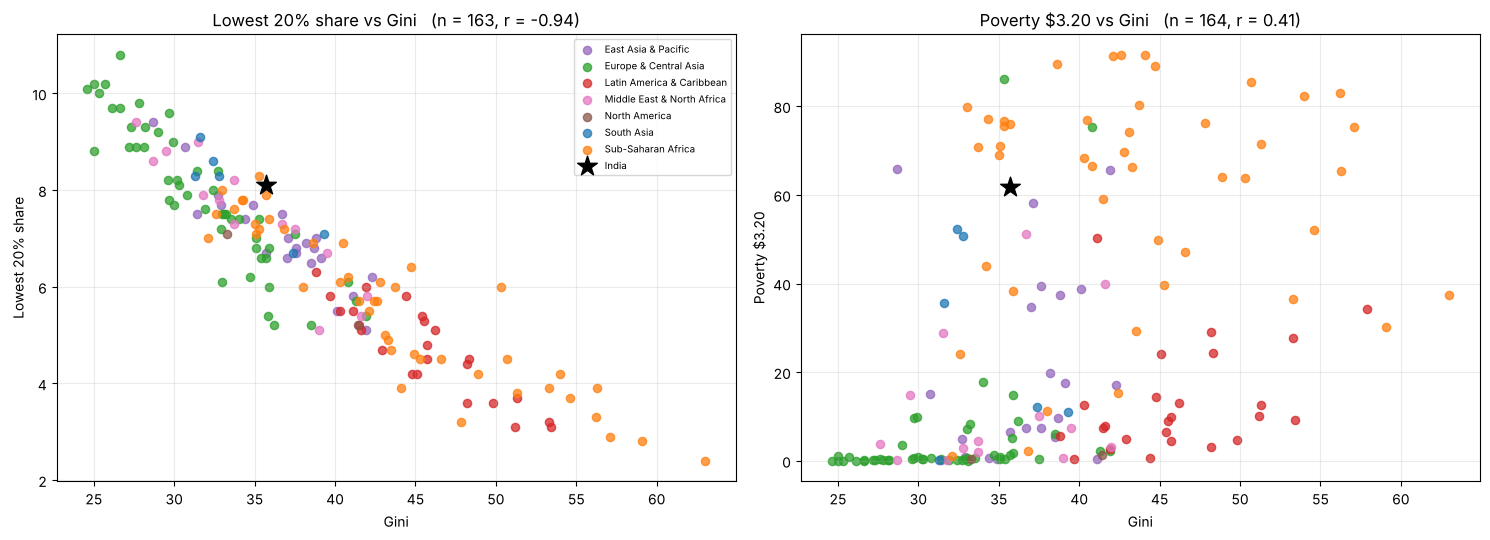

In [ ]:
pairs = [("Gini", "Lowest 20% share"), ("Gini", "Poverty $3.20")]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
regions = cross["Region"].dropna().unique()
colors = dict(zip(regions, plt.cm.tab10(np.arange(len(regions)))))

for ax, (xv, yv) in zip(axes, pairs):
    sub = cross[[xv, yv, "Region"]].dropna()
    for reg, grp in sub.groupby("Region"):
        ax.scatter(grp[xv], grp[yv], s=35, alpha=0.75, color=colors[reg], label=reg)
    ax.scatter(india_cross[xv], india_cross[yv], s=220, marker="*", color="black", label="India", zorder=5)
    ax.set_xlabel(xv); ax.set_ylabel(yv)
    ax.set_title(f"{yv} vs {xv}   (n = {len(sub)}, r = {sub[xv].corr(sub[yv]):.2f})")
axes[0].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

### 4.4 Grouped Bar Chart: First vs Latest Available Observation

A grouped bar chart makes the change between the first and latest observation easier to compare. The years differ across indicators, so this compares each indicator's own endpoints — not one common time period.

,Indicator,First,Latest,First year,Latest year
0,Poverty headcount ratio at $3.20 a day (2011 P...,88.7,61.7,1977,2011
1,Poverty headcount ratio at national poverty li...,45.3,21.9,1993,2011
2,Gini index (World Bank estimate),32.1,35.7,1983,2011
3,Income share held by lowest 20%,8.5,8.1,1983,2011


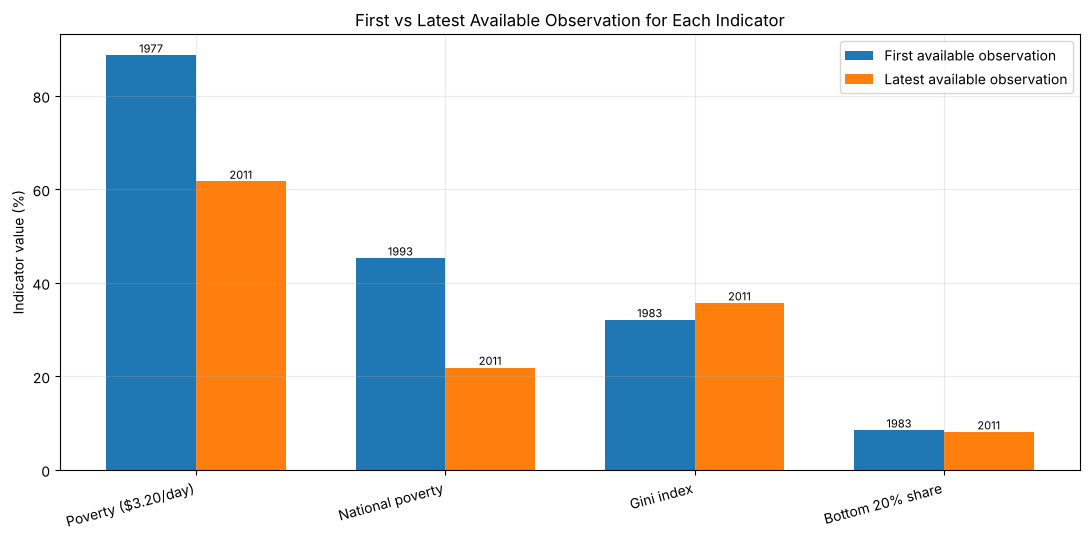

In [ ]:
# Build endpoint comparison data from the available observations
endpoint_rows = []

for indicator in selected_indicators:
    subset = analysis_data[analysis_data["Indicator Name"] == indicator].sort_values("Year")
    if not subset.empty:
        endpoint_rows.append({
            "Indicator": indicator,
            "First": subset.iloc[0]["Value"],
            "Latest": subset.iloc[-1]["Value"],
            "First year": int(subset.iloc[0]["Year"]),
            "Latest year": int(subset.iloc[-1]["Year"])
        })

endpoint_df = pd.DataFrame(endpoint_rows)
display(endpoint_df.round(2))

x = np.arange(len(endpoint_df))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(x - width/2, endpoint_df["First"], width,
       label="First available observation")
ax.bar(x + width/2, endpoint_df["Latest"], width,
       label="Latest available observation")

ax.set_xticks(x)
ax.set_xticklabels(
    ["Poverty ($3.20/day)", "National poverty", "Gini index", "Bottom 20% share"],
    rotation=15, ha="right"
)
ax.set_ylabel("Indicator value (%)")
ax.set_title("First vs Latest Available Observation for Each Indicator")
ax.legend()
ax.grid(axis="y", alpha=0.25)

for i, row in endpoint_df.iterrows():
    ax.text(i - width/2, row["First"], f'{row["First year"]}',
            ha="center", va="bottom", fontsize=8)
    ax.text(i + width/2, row["Latest"], f'{row["Latest year"]}',
            ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

### 4.5 Populations and Samples

- A **population** is the complete set of units about which we want to draw conclusions; a numerical summary of a population is a **parameter** (e.g. $\mu$, $\sigma$, $p$).
- A **sample** is a subset of the population actually observed; a numerical summary of a sample is a **statistic** (e.g. $\bar{x}$, $s$, $\hat{p}$).

Here the **population** is the set of all countries with a Gini estimate in the workbook. A **simple random sample** (each country equally likely, no repetition) of size $n = 30$ is drawn and its statistics are compared with the population parameters.

$$
\mu = \frac{1}{N}\sum_{i=1}^{N} X_i, \qquad
\sigma = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(X_i-\mu)^2}, \qquad
s = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}
$$

India's six survey-year Gini values can similarly be treated as a (non-random) **sample** of India's inequality over time.

,Quantity,Population parameter (N = 164),Sample statistic (n = 30)
0,Mean,38.27,41.04
1,Standard deviation,7.89,8.07
2,Median,37.05,40.55
3,Minimum,24.60,25.00
4,Maximum,63.00,57.90


Means of five different random samples of size 30: [36.12 39.73 36.64 37.89 38.68]
Population mean: 38.27  -> sample means fluctuate around it (sampling variability)


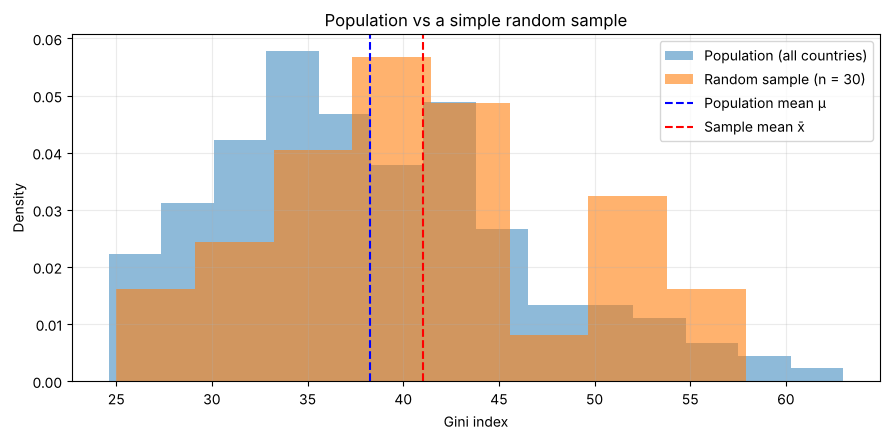

In [ ]:
rng = np.random.default_rng(42)

N = len(gini_pop)
sample30 = gini_pop.sample(n=30, replace=False, random_state=42)

comparison = pd.DataFrame({
    "Quantity": ["Mean", "Standard deviation", "Median", "Minimum", "Maximum"],
    "Population parameter (N = %d)" % N: [gini_pop.mean(), gini_pop.std(ddof=0), gini_pop.median(),
                                           gini_pop.min(), gini_pop.max()],
    "Sample statistic (n = 30)":         [sample30.mean(), sample30.std(ddof=1), sample30.median(),
                                           sample30.min(), sample30.max()],
})
display(comparison.round(2))

# How much do sample means vary from sample to sample?
five_means = [gini_pop.sample(30, random_state=s).mean() for s in range(5)]
print("Means of five different random samples of size 30:", np.round(five_means, 2))
print(f"Population mean: {gini_pop.mean():.2f}  -> sample means fluctuate around it (sampling variability)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(gini_pop, bins=14, alpha=0.5, density=True, label="Population (all countries)")
ax.hist(sample30, bins=8, alpha=0.6, density=True, label="Random sample (n = 30)")
ax.axvline(gini_pop.mean(), color="blue", linestyle="--", label="Population mean μ")
ax.axvline(sample30.mean(), color="red", linestyle="--", label="Sample mean x̄")
ax.set_xlabel("Gini index"); ax.set_ylabel("Density"); ax.legend()
ax.set_title("Population vs a simple random sample")
plt.tight_layout(); plt.show()

## 5. Measures of Central Tendency and Dispersion, Percentiles and Box Plots

Since the dataset contains observations for selected survey years rather than every year, all calculations use **available non-missing observations only**.

### 5.1 Descriptive Statistics for India's Indicators

For observations $x_1, x_2, \ldots, x_n$, the arithmetic mean is calculated as:

$$
\boxed{\bar{x} = \frac{\sum_{i=1}^{n} x_i}{n}}
$$

The median is the middle value after arranging the observations in ascending order. The range and sample standard deviation are calculated as follows:

**Range:**

$$
\boxed{\text{Range} = X_{\max} - X_{\min}}
$$

**Sample Standard Deviation:**

$$
\boxed{s = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}}
$$

The coefficient of variation (CV) expresses the sample standard deviation relative to the mean:

$$
\boxed{CV = \frac{s}{\bar{x}} \times 100}
$$

**Where:**
- $x_i$ = Individual observation
- $n$ = Total number of observations
- $\bar{x}$ = Arithmetic mean
- $s$ = Sample standard deviation
- $X_{\max}$ = Maximum observation
- $X_{\min}$ = Minimum observation

**Note:** CV is included as a descriptive measure, but comparisons across indicators should be made cautiously because the indicators represent different concepts and scales.

In [ ]:
# Calculate descriptive statistics for each selected indicator
descriptive_rows = []

for indicator in selected_indicators:
    values = (
        analysis_data.loc[analysis_data["Indicator Name"] == indicator, "Value"]
        .dropna()
        .astype(float)
    )

    if len(values) > 0:
        mean_value = values.mean()
        sd_value = values.std(ddof=1) if len(values) > 1 else np.nan

        descriptive_rows.append({
            "Indicator": indicator,
            "Count (n)": len(values),
            "Mean": mean_value,
            "Median": values.median(),
            "Minimum": values.min(),
            "Maximum": values.max(),
            "Range": values.max() - values.min(),
            "Sample SD": sd_value,
            "CV (%)": (sd_value / mean_value * 100)
                      if pd.notna(sd_value) and mean_value != 0 else np.nan
        })

descriptive_stats = pd.DataFrame(descriptive_rows)
print("Descriptive statistics (calculated from available observations):")
display(descriptive_stats.round(2))

Descriptive statistics (calculated from available observations):


,Indicator,Count (n),Mean,Median,Minimum,Maximum,Range,Sample SD,CV (%)
0,Poverty headcount ratio at $3.20 a day (2011 P...,7,78.47,81.9,61.7,88.7,27.0,9.53,12.14
1,Poverty headcount ratio at national poverty li...,4,33.55,33.5,21.9,45.3,23.4,10.02,29.86
2,Gini index (World Bank estimate),6,33.65,33.5,31.7,35.7,4.0,1.74,5.17
3,Income share held by lowest 20%,6,8.50,8.5,8.1,8.9,0.8,0.28,3.33


### 5.2 Frequency Distribution Tables

A frequency distribution groups numerical observations into class intervals and records the number of observations falling within each interval.

**Relative Frequency:**

$$
\boxed{\text{Relative Frequency} = \frac{f}{N}}
$$

**Percentage Frequency:**

$$
\boxed{\text{Percentage Frequency} = \frac{f}{N} \times 100}
$$

**Cumulative Frequency:**

$$
\boxed{CF = \sum_{i=1}^{k} f_i}
$$

**Where:**
- $f$ = Frequency of an individual class interval
- $N$ = Total number of observations
- $f_i$ = Frequency of the $i^{th}$ class interval
- $k$ = Number of class intervals
- $CF$ = Cumulative frequency

These measures help identify the distribution, proportion and cumulative count of observations across different value ranges.

In [ ]:
# Construct frequency tables using meaningful intervals for each indicator
frequency_bins = {
    selected_indicators[0]: [60, 70, 80, 90, 100],
    selected_indicators[1]: [0, 10, 20, 30, 40, 50, 60],
    selected_indicators[2]: [30, 32, 34, 36, 38, 40],
    selected_indicators[3]: [7, 8, 9, 10, 11]
}

frequency_tables = {}

for indicator, bins in frequency_bins.items():
    values = analysis_data.loc[
        analysis_data["Indicator Name"] == indicator, "Value"
    ].dropna()

    if len(values) == 0:
        continue

    categories = pd.cut(values, bins=bins, right=False, include_lowest=True)
    freq = categories.value_counts(sort=False)
    table = pd.DataFrame({
        "Class interval": [str(interval) for interval in freq.index],
        "Frequency (f)": freq.values
    })
    table["Relative frequency"] = table["Frequency (f)"] / len(values)
    table["Percentage (%)"] = table["Relative frequency"] * 100
    table["Cumulative frequency"] = table["Frequency (f)"].cumsum()

    frequency_tables[indicator] = table
    print("\n" + indicator)
    display(table.round(3))


Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population)


,Class interval,Frequency (f),Relative frequency,Percentage (%),Cumulative frequency
0,"[60, 70)",1,0.143,14.286,1
1,"[70, 80)",2,0.286,28.571,3
2,"[80, 90)",4,0.571,57.143,7
3,"[90, 100)",0,0.000,0.000,7



Poverty headcount ratio at national poverty lines (% of population)


,Class interval,Frequency (f),Relative frequency,Percentage (%),Cumulative frequency
0,"[0, 10)",0,0.00,0.0,0
1,"[10, 20)",0,0.00,0.0,0
2,"[20, 30)",2,0.50,50.0,2
3,"[30, 40)",1,0.25,25.0,3
4,"[40, 50)",1,0.25,25.0,4
5,"[50, 60)",0,0.00,0.0,4



Gini index (World Bank estimate)


,Class interval,Frequency (f),Relative frequency,Percentage (%),Cumulative frequency
0,"[30, 32)",1,0.167,16.667,1
1,"[32, 34)",2,0.333,33.333,3
2,"[34, 36)",3,0.500,50.000,6
3,"[36, 38)",0,0.000,0.000,6
4,"[38, 40)",0,0.000,0.000,6



Income share held by lowest 20%


,Class interval,Frequency (f),Relative frequency,Percentage (%),Cumulative frequency
0,"[7, 8)",0,0.0,0.0,0
1,"[8, 9)",6,1.0,100.0,6
2,"[9, 10)",0,0.0,0.0,6
3,"[10, 11)",0,0.0,0.0,6


### 5.3 Mean, Median and Mode (raw and grouped data)

**Mean** (balance point), **median** (middle value) and **mode** (most frequent value / most crowded class) describe the centre of a distribution. For a **grouped frequency table** with class width $h$:

$$
\boxed{\bar{x} = \frac{\sum f_i m_i}{N}}\qquad
\boxed{\text{Median} = L + \frac{N/2 - CF_{\text{prev}}}{f_{\text{med}}}\times h}\qquad
\boxed{\text{Mode} = L + \frac{f_1 - f_0}{2f_1 - f_0 - f_2}\times h}
$$

where $m_i$ = class mid-point, $L$ = lower limit of the median/modal class, $CF_{\text{prev}}$ = cumulative frequency before the median class, $f_1$ = frequency of the modal class, and $f_0, f_2$ = frequencies of the classes before and after it.

For a **symmetric** distribution mean ≈ median ≈ mode; for a **right-skewed** one, mean > median > mode.

In [ ]:
def grouped_measures(values, bins):
    """Mean, median and mode from a grouped frequency table."""
    values = pd.Series(values).dropna()
    freq, edges = np.histogram(values, bins=bins)
    mid = (edges[:-1] + edges[1:]) / 2
    h = edges[1] - edges[0]
    N = freq.sum()
    mean_g = (freq * mid).sum() / N
    cf = freq.cumsum()
    m = np.argmax(cf >= N / 2)                          # median class
    cf_prev = cf[m - 1] if m > 0 else 0
    median_g = edges[m] + (N / 2 - cf_prev) / freq[m] * h
    k = np.argmax(freq)                                 # modal class
    f0 = freq[k - 1] if k > 0 else 0
    f2 = freq[k + 1] if k < len(freq) - 1 else 0
    mode_g = edges[k] + (freq[k] - f0) / (2 * freq[k] - f0 - f2) * h
    table = pd.DataFrame({"Class": [f"{edges[i]:.0f}–{edges[i+1]:.0f}" for i in range(len(freq))],
                          "f": freq, "Mid-point": mid, "Cumulative f": cf})
    return table, mean_g, median_g, mode_g

table, mean_g, median_g, mode_g = grouped_measures(gini_pop, bins=np.arange(20, 70, 5))
print("Grouped frequency table of the cross-country Gini index (class width = 5)")
display(table)

# Mode of raw data: values rounded to the nearest integer (continuous data rarely repeat exactly)
raw_mode = gini_pop.round(0).mode().tolist()

central = pd.DataFrame({
    "Measure": ["Mean", "Median", "Mode"],
    "Raw data": [gini_pop.mean(), gini_pop.median(), raw_mode[0]],
    "Grouped data (formula)": [mean_g, median_g, mode_g],
})
display(central.round(2))
print(f"Skewness of Gini = {stats.skew(gini_pop):.2f}  (positive => mean > median: slightly right-skewed)")

# Same measures for India's four indicators (small n -> mode may not exist)
print("\nMode of India's indicator values (rounded to 1 decimal):")
for ind in selected_indicators:
    s = indicator_wide[ind].dropna().round(1)
    m = s.mode()
    print(f"  {ind[:60]:<60} -> ", "no repeated value (no mode)" if s.value_counts().max() == 1 else m.tolist())

Grouped frequency table of the cross-country Gini index (class width = 5)


,Class,f,Mid-point,Cumulative f
0,20–25,1,22.5,1
1,25–30,22,27.5,23
2,30–35,38,32.5,61
3,35–40,40,37.5,101
4,40–45,33,42.5,134
5,45–50,14,47.5,148
6,50–55,10,52.5,158
7,55–60,5,57.5,163
8,60–65,1,62.5,164


,Measure,Raw data,Grouped data (formula)
0,Mean,38.27,38.45
1,Median,37.05,37.62
2,Mode,33.00,36.11


Skewness of Gini = 0.65  (positive => mean > median: slightly right-skewed)

Mode of India's indicator values (rounded to 1 decimal):
  Poverty headcount ratio at $3.20 a day (2011 PPP) (% of popu ->  no repeated value (no mode)
  Poverty headcount ratio at national poverty lines (% of popu ->  no repeated value (no mode)
  Gini index (World Bank estimate)                             ->  no repeated value (no mode)
  Income share held by lowest 20%                              ->  [8.5]


### 5.4 Variance and Standard Deviation

Variance measures the average squared deviation from the mean. The **population** and **sample** versions are:

$$
\boxed{\sigma^2 = \frac{\sum_{i=1}^{N}(X_i-\mu)^2}{N}}\qquad
\boxed{s^2 = \frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}
$$

Dividing by $n-1$ (**Bessel's correction**) makes $s^2$ an unbiased estimator of $\sigma^2$. The standard deviation is the positive square root and is in the same units as the data. A useful shortcut is $s^2 = \dfrac{1}{n-1}\left[\sum x_i^2 - n\bar{x}^2\right]$.

In [ ]:
rows = []
for label, vals in [("Cross-country Gini (population, N=%d)" % len(gini_pop), gini_pop),
                    ("Cross-country Gini (random sample, n=30)", sample30),
                    ("India Gini (6 survey years)", indicator_wide[selected_indicators[2]].dropna()),
                    ("India poverty $3.20/day (7 survey years)", indicator_wide[selected_indicators[0]].dropna())]:
    x = np.asarray(vals, dtype=float); n = len(x)
    manual_var = ((x - x.mean()) ** 2).sum() / (n - 1)             # definition
    shortcut_var = (np.sum(x ** 2) - n * x.mean() ** 2) / (n - 1)  # computational shortcut
    rows.append({"Data": label, "n": n,
                 "Population variance (÷n)": np.var(x, ddof=0),
                 "Sample variance (÷n−1)": manual_var,
                 "Shortcut formula": shortcut_var,
                 "Sample SD": np.sqrt(manual_var)})
display(pd.DataFrame(rows).round(3))
print("Manual, shortcut and NumPy (ddof=1) sample variances agree; the ÷n version is always slightly smaller.")

,Data,n,Population variance (÷n),Sample variance (÷n−1),Shortcut formula,Sample SD
0,"Cross-country Gini (population, N=164)",164,62.327,62.710,62.710,7.919
1,"Cross-country Gini (random sample, n=30)",30,62.919,65.089,65.089,8.068
2,India Gini (6 survey years),6,2.522,3.027,3.027,1.740
3,India poverty $3.20/day (7 survey years),7,77.811,90.779,90.779,9.528


Manual, shortcut and NumPy (ddof=1) sample variances agree; the ÷n version is always slightly smaller.


### 5.5 Percentiles, Quartiles and the Interquartile Range

The **$p$-th percentile** is the value below which $p\%$ of the observations fall. With $n$ ordered observations, its position is

$$
\boxed{\text{position} = \frac{p}{100}(n-1) + 1}
$$

(linear interpolation between neighbouring order statistics). The quartiles are $Q_1 = P_{25}$, $Q_2 = P_{50}$ (median), $Q_3 = P_{75}$, and

$$
\boxed{IQR = Q_3 - Q_1}\qquad \text{Outlier fences: } Q_1 - 1.5\,IQR \ \text{ and } \ Q_3 + 1.5\,IQR
$$

The **percentile rank** of a value tells what percentage of the population lies at or below it.

In [ ]:
pct_levels = [5, 10, 25, 50, 75, 90, 95]
pct_table = pd.DataFrame({
    "Percentile": [f"P{p}" for p in pct_levels],
    "Gini": np.percentile(gini_pop, pct_levels),
    "Poverty $3.20 (%)": np.percentile(pov320_pop, pct_levels),
    "Lowest 20% share (%)": np.percentile(cross["Lowest 20% share"].dropna(), pct_levels),
})
display(pct_table.round(2))

q1, q2, q3 = np.percentile(gini_pop, [25, 50, 75])
iqr = q3 - q1
print(f"Gini: Q1 = {q1:.2f}, Median = {q2:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Outlier fences: lower = {q1 - 1.5*iqr:.2f}, upper = {q3 + 1.5*iqr:.2f}")

print("\nPercentile rank of India's latest values among all countries:")
for var in ["Gini", "Poverty $3.20", "Lowest 20% share"]:
    pr = stats.percentileofscore(cross[var].dropna(), india_cross[var], kind="weak")
    print(f"  {var:<18} India = {india_cross[var]:>5.1f}  -> percentile rank ≈ {pr:.1f}")

,Percentile,Gini,Poverty $3.20 (%),Lowest 20% share (%)
0,P5,27.22,0.10,3.60
1,P10,28.79,0.20,4.20
2,P25,32.78,1.12,5.35
3,P50,37.05,10.20,6.80
4,P75,42.65,51.10,7.85
5,P90,49.53,75.40,8.98
6,P95,53.38,80.53,9.58


Gini: Q1 = 32.77, Median = 37.05, Q3 = 42.65, IQR = 9.88
Outlier fences: lower = 17.96, upper = 57.46

Percentile rank of India's latest values among all countries:
  Gini               India =  35.7  -> percentile rank ≈ 44.5
  Poverty $3.20      India =  61.7  -> percentile rank ≈ 79.8
  Lowest 20% share   India =   8.1  -> percentile rank ≈ 79.8


### 5.6 Box Plots

A **box plot** (five-number summary) displays the minimum, $Q_1$, median, $Q_3$ and maximum. The box spans the IQR; the whiskers extend to the most extreme points within the fences $Q_1-1.5\,IQR$ and $Q_3+1.5\,IQR$; points beyond them are drawn individually as **outliers**. Placing box plots side by side compares both centre and spread across groups.

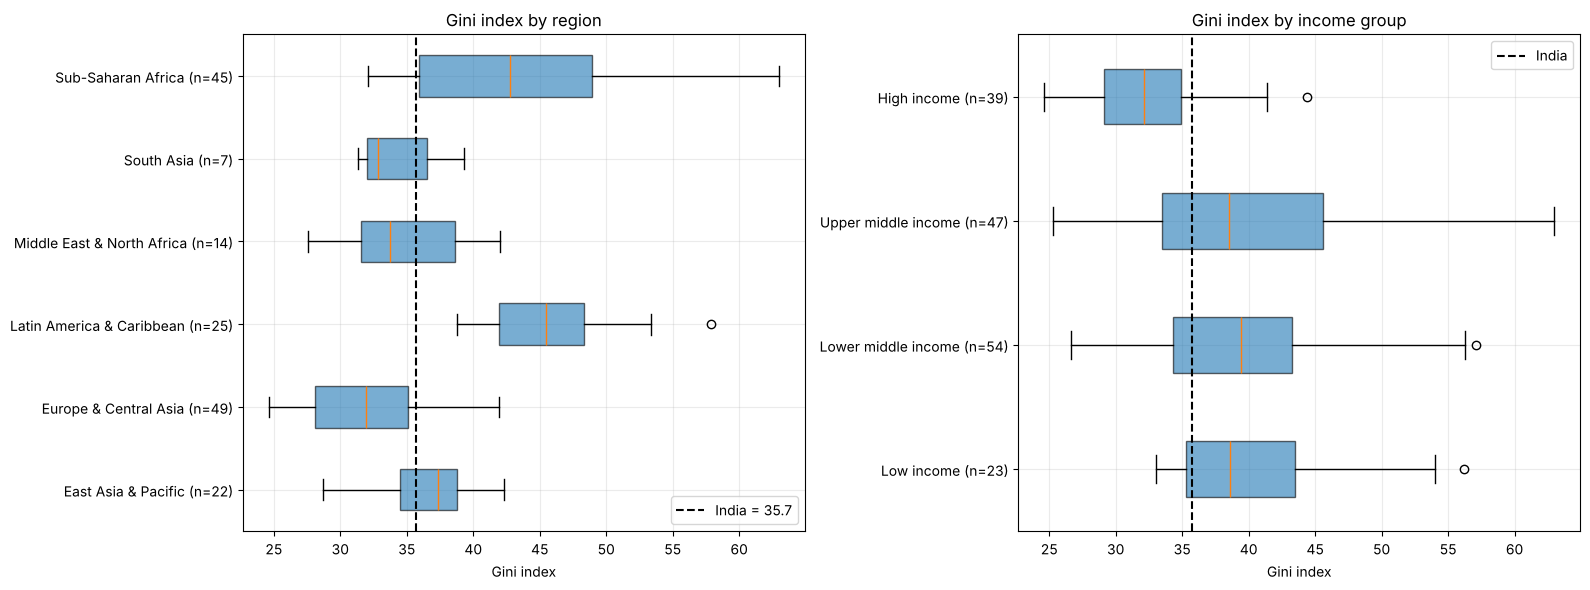

,count,min,25%,50%,75%,max
Region,,,,,,
East Asia & Pacific,22.0,28.7,34.5,37.4,38.8,42.3
Europe & Central Asia,49.0,24.6,28.1,31.9,35.1,41.9
Latin America & Caribbean,25.0,38.8,41.9,45.5,48.3,57.9
Middle East & North Africa,14.0,27.6,31.6,33.7,38.6,42.0
North America,2.0,33.3,35.3,37.3,39.4,41.4
South Asia,7.0,31.3,32.0,32.8,36.6,39.3
Sub-Saharan Africa,45.0,32.1,35.9,42.8,48.9,63.0


Countries flagged as Gini outliers by the 1.5×IQR rule:


,Short Name,Region,Gini
0,South Africa,Sub-Saharan Africa,63.0
1,Namibia,Sub-Saharan Africa,59.1
2,Suriname,Latin America & Caribbean,57.9


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# (a) Gini by region
grp = [(r, g["Gini"].dropna().values) for r, g in cross.groupby("Region") if g["Gini"].notna().sum() >= 5]
bp = axes[0].boxplot([v for _, v in grp], vert=False, patch_artist=True)
axes[0].set_yticklabels([f"{r} (n={len(v)})" for r, v in grp])
for patch in bp["boxes"]:
    patch.set_alpha(0.6)
axes[0].axvline(india_cross["Gini"], color="black", linestyle="--", label=f"India = {india_cross['Gini']}")
axes[0].set_xlabel("Gini index"); axes[0].set_title("Gini index by region"); axes[0].legend()

# (b) Gini by income group
order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
grp2 = [(g, cross.loc[cross["Income Group"] == g, "Gini"].dropna().values) for g in order]
bp2 = axes[1].boxplot([v for _, v in grp2], vert=False, patch_artist=True)
axes[1].set_yticklabels([f"{g} (n={len(v)})" for g, v in grp2])
for patch in bp2["boxes"]:
    patch.set_alpha(0.6)
axes[1].axvline(india_cross["Gini"], color="black", linestyle="--", label="India")
axes[1].set_xlabel("Gini index"); axes[1].set_title("Gini index by income group"); axes[1].legend()
plt.tight_layout(); plt.show()

# Five-number summary table by region
five = cross.groupby("Region")["Gini"].describe()[["count", "min", "25%", "50%", "75%", "max"]]
display(five.round(1))

# Outliers by the 1.5 x IQR rule (whole cross-country sample)
outliers = cross.loc[(cross["Gini"] < q1 - 1.5 * iqr) | (cross["Gini"] > q3 + 1.5 * iqr),
                     ["Short Name", "Region", "Gini"]]
print("Countries flagged as Gini outliers by the 1.5×IQR rule:")
display(outliers.sort_values("Gini", ascending=False).reset_index(drop=True))

## 6. Curve Fitting, Correlation, Regression and Rank Correlation

### 6.1 Curve Fitting by the Method of Least Squares

The **method of least squares** chooses the curve whose **sum of squared residuals** $S = \sum (y_i - \hat{y}_i)^2$ is smallest.

**Straight line** $y = a + bx$ — the *normal equations* are

$$
\boxed{\sum y = na + b\sum x}\qquad\qquad
\boxed{\sum xy = a\sum x + b\sum x^2}
$$

**Second-degree parabola** $y = a + bx + cx^2$ — the *normal equations* are

$$
\boxed{\begin{aligned}
\sum y &= na + b\sum x + c\sum x^2\\
\sum xy &= a\sum x + b\sum x^2 + c\sum x^3\\
\sum x^2y &= a\sum x^2 + b\sum x^3 + c\sum x^4
\end{aligned}}
$$

Goodness of fit is measured by the coefficient of determination and the standard error of estimate:

$$
R^2 = 1 - \frac{SSE}{SST} = 1 - \frac{\sum(y_i-\hat{y}_i)^2}{\sum(y_i-\bar{y})^2},\qquad
\bar{R}^2 = 1 - (1-R^2)\frac{n-1}{n-k-1},\qquad
s_e = \sqrt{\frac{SSE}{n-k-1}}
$$

($k$ = number of predictors: 1 for the line, 2 for the parabola.) Adjusted $\bar{R}^2$ is used because $R^2$ always rises when a term is added.

Time is coded as $x = \text{Year} - 1990$ to keep the sums small. The fits are done for India's **poverty headcount at $3.20/day** and **Gini index**.

=== Poverty headcount at $3.20/day (%) (n = 7) ===
Sums for the normal equations: {'n': 7.0, 'Σx': 34.0, 'Σx²': 1234.0, 'Σx³': 16324.0, 'Σx⁴': 394342.0, 'Σy': 549.3, 'Σxy': 1949.9, 'Σx²y': 88479.5}
Straight line : y = 81.735 + (-0.672)x
Parabola      : y = 84.111 + (-0.494)x + (-0.0184)x²   [x = Year − 1990]

=== Gini index (n = 6) ===
Sums for the normal equations: {'n': 6.0, 'Σx': 47.0, 'Σx²': 1065.0, 'Σx³': 18521.0, 'Σx⁴': 365781.0, 'Σy': 201.9, 'Σxy': 1676.5, 'Σx²y': 37417.1}
Straight line : y = 32.583 + (0.136)x
Parabola      : y = 32.149 + (0.036)x + (0.0069)x²   [x = Year − 1990]



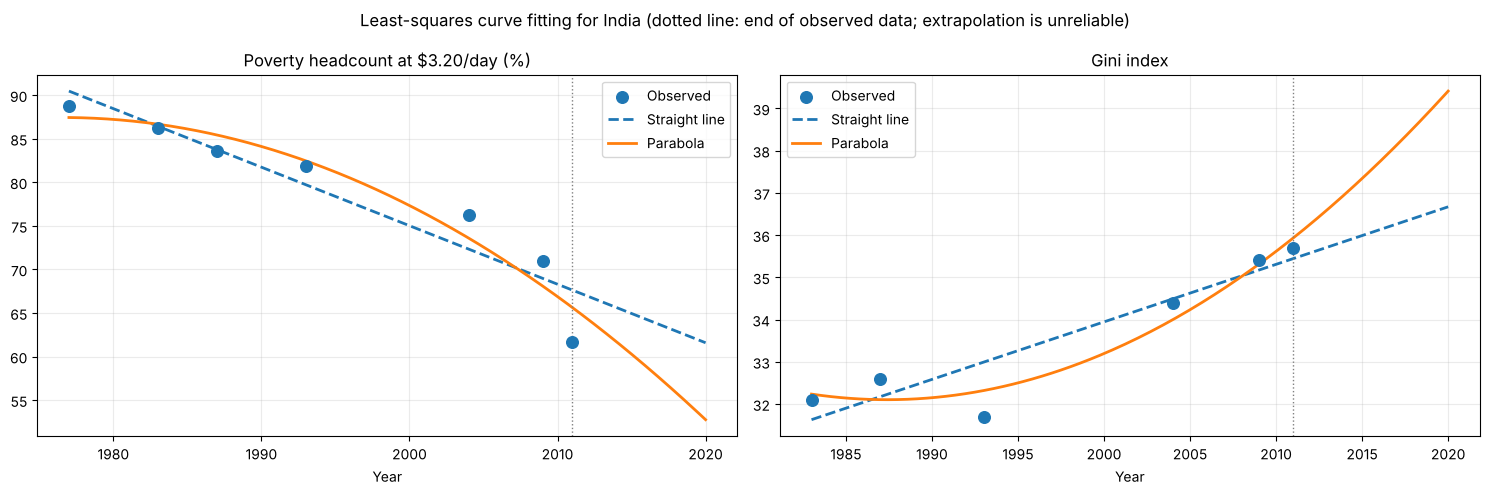

,Series,Model,SSE,R²,Adjusted R²,Std. error of estimate
0,Poverty headcount at $3.20/day (%),Straight line,62.188,0.886,0.863,3.527
1,Poverty headcount at $3.20/day (%),Parabola,36.222,0.933,0.900,3.009
2,Gini index,Straight line,2.197,0.855,0.819,0.741
3,Gini index,Parabola,0.871,0.942,0.904,0.539


In [ ]:
def fit_poly_normal_equations(x, y, degree):
    """Solve the least-squares normal equations for a polynomial of given degree."""
    A = np.array([[np.sum(x ** (i + j)) for j in range(degree + 1)] for i in range(degree + 1)])
    rhs = np.array([np.sum((x ** i) * y) for i in range(degree + 1)])
    return np.linalg.solve(A, rhs), A, rhs

def fit_quality(x, y, coef):
    yhat = sum(c * x ** i for i, c in enumerate(coef))
    sse = np.sum((y - yhat) ** 2); sst = np.sum((y - y.mean()) ** 2)
    n, k = len(y), len(coef) - 1
    r2 = 1 - sse / sst
    adj = 1 - (1 - r2) * (n - 1) / (n - k - 1) if n - k - 1 > 0 else np.nan
    se = np.sqrt(sse / (n - k - 1)) if n - k - 1 > 0 else np.nan
    return yhat, sse, r2, adj, se

series_to_fit = {
    "Poverty headcount at $3.20/day (%)": indicator_wide[selected_indicators[0]].dropna(),
    "Gini index": indicator_wide[selected_indicators[2]].dropna(),
}

fit_summary = []
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (label, s) in zip(axes, series_to_fit.items()):
    years = s.index.values.astype(float); x = years - 1990; y = s.values
    n = len(x)

    # Sums required by the normal equations
    sums = {"n": n, "Σx": x.sum(), "Σx²": (x**2).sum(), "Σx³": (x**3).sum(), "Σx⁴": (x**4).sum(),
            "Σy": y.sum(), "Σxy": (x*y).sum(), "Σx²y": (x**2*y).sum()}
    print(f"=== {label} (n = {n}) ===")
    print("Sums for the normal equations:", {k: round(float(v), 2) for k, v in sums.items()})

    line, _, _ = fit_poly_normal_equations(x, y, 1)
    para, _, _ = fit_poly_normal_equations(x, y, 2)
    # Cross-check against NumPy's built-in least squares
    assert np.allclose(line, np.polyfit(x, y, 1)[::-1]) and np.allclose(para, np.polyfit(x, y, 2)[::-1])

    print(f"Straight line : y = {line[0]:.3f} + ({line[1]:.3f})x")
    print(f"Parabola      : y = {para[0]:.3f} + ({para[1]:.3f})x + ({para[2]:.4f})x²   [x = Year − 1990]")

    for name, coef in [("Straight line", line), ("Parabola", para)]:
        _, sse, r2, adj, se = fit_quality(x, y, coef)
        fit_summary.append({"Series": label, "Model": name, "SSE": sse, "R²": r2,
                            "Adjusted R²": adj, "Std. error of estimate": se})

    xx = np.linspace(x.min(), x.max() + 9, 200)
    ax.scatter(years, y, s=70, zorder=3, label="Observed")
    ax.plot(xx + 1990, line[0] + line[1] * xx, "--", linewidth=2, label="Straight line")
    ax.plot(xx + 1990, para[0] + para[1] * xx + para[2] * xx ** 2, linewidth=2, label="Parabola")
    ax.axvline(years.max(), color="grey", linestyle=":", linewidth=1)
    ax.set_title(label); ax.set_xlabel("Year"); ax.legend()
    print()

fig.suptitle("Least-squares curve fitting for India (dotted line: end of observed data; extrapolation is unreliable)")
plt.tight_layout(); plt.show()

display(pd.DataFrame(fit_summary).round(3))

**Reading the results.** The parabola always has $R^2$ at least as high as the line, so the **adjusted $R^2$** and the standard error of estimate decide whether the extra curvature term is worthwhile. With only 6–7 data points, a quadratic can fit well within the observed range but extrapolate badly outside it, so the fitted curves are used to *describe* the observed pattern — not to forecast.

### 6.2 Pearson Correlation Analysis

Pearson's correlation coefficient measures the **direction and strength of a linear association** between two numerical variables.

The formula for Pearson's correlation coefficient is:

$$
\boxed{
r =
\frac{
\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
}{
\sqrt{
\sum_{i=1}^{n}(x_i-\bar{x})^2
\sum_{i=1}^{n}(y_i-\bar{y})^2
}
}
}
$$

**Where:**
- $r$ = Pearson correlation coefficient
- $x_i, y_i$ = Individual observations of two variables
- $\bar{x}, \bar{y}$ = Arithmetic means of the respective variables
- $n$ = Number of paired observations

The value of $r$ lies between $-1$ and $+1$:

- $r = +1$: Perfect positive correlation
- $r = -1$: Perfect negative correlation
- $r = 0$: No linear correlation

A positive value indicates a positive linear association, while a negative value indicates a negative linear association. A value near zero indicates a weak linear association.

**Note:** Correlation does not establish causation.

Pearson correlation matrix:


,Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population),Poverty headcount ratio at national poverty lines (% of population),Gini index (World Bank estimate),Income share held by lowest 20%
Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population),1.000,0.990,-0.915,0.815
Poverty headcount ratio at national poverty lines (% of population),0.990,1.000,-0.925,0.985
Gini index (World Bank estimate),-0.915,-0.925,1.000,-0.878
Income share held by lowest 20%,0.815,0.985,-0.878,1.000


Number of paired years used for each correlation:


,Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population),Poverty headcount ratio at national poverty lines (% of population),Gini index (World Bank estimate),Income share held by lowest 20%
Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population),7,4,6,6
Poverty headcount ratio at national poverty lines (% of population),4,4,4,4
Gini index (World Bank estimate),6,4,6,6
Income share held by lowest 20%,6,4,6,6


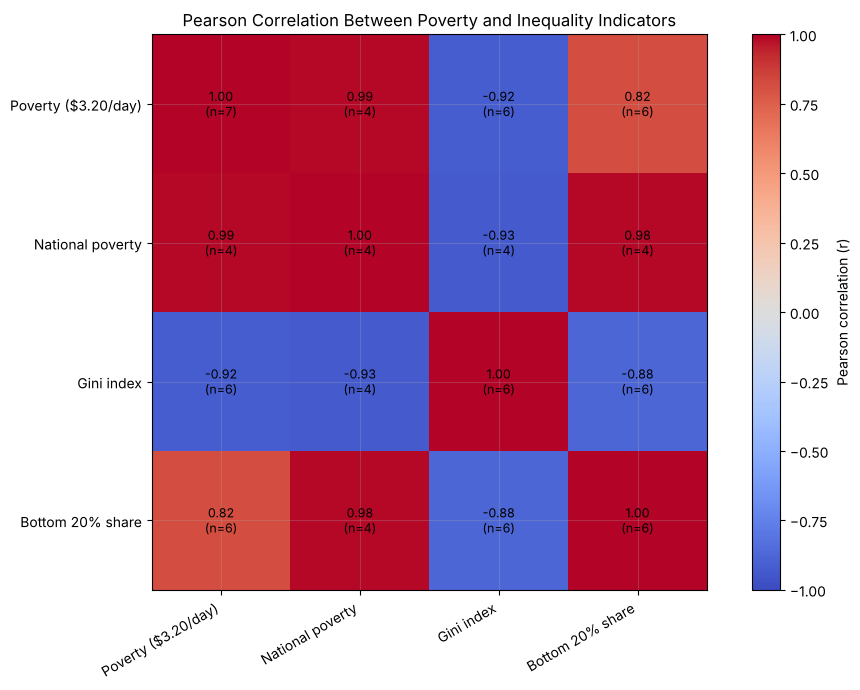

In [ ]:
# Create a year-by-indicator table for correlation analysis
indicator_year_data = {}

for indicator in selected_indicators:
    subset = analysis_data[analysis_data["Indicator Name"] == indicator]
    indicator_year_data[indicator] = subset.set_index("Year")["Value"]

indicator_wide = pd.DataFrame(indicator_year_data)

# Pearson correlation uses only years where both indicators have observations
correlation_matrix = indicator_wide.corr(method="pearson")
pair_count_matrix = indicator_wide.notna().astype(int).T.dot(
    indicator_wide.notna().astype(int)
)

print("Pearson correlation matrix:")
display(correlation_matrix.round(3))

print("Number of paired years used for each correlation:")
display(pair_count_matrix)

# Heatmap-style correlation plot using Matplotlib
fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(selected_indicators)))
ax.set_yticks(range(len(selected_indicators)))
short_names = [
    "Poverty ($3.20/day)",
    "National poverty",
    "Gini index",
    "Bottom 20% share"
]
ax.set_xticklabels(short_names, rotation=30, ha="right")
ax.set_yticklabels(short_names)

for i in range(len(selected_indicators)):
    for j in range(len(selected_indicators)):
        value = correlation_matrix.iloc[i, j]
        count = pair_count_matrix.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}\n(n={count})",
                    ha="center", va="center", fontsize=9)

ax.set_title("Pearson Correlation Between Poverty and Inequality Indicators")
fig.colorbar(image, ax=ax, label="Pearson correlation (r)")
plt.tight_layout()
plt.show()

### 6.3 Scatter Plots with Fitted Lines for India

Scatter plots help inspect the direction and approximate linear pattern between two indicators. The fitted line is a descriptive least-squares trend line, not evidence of a causal relationship.

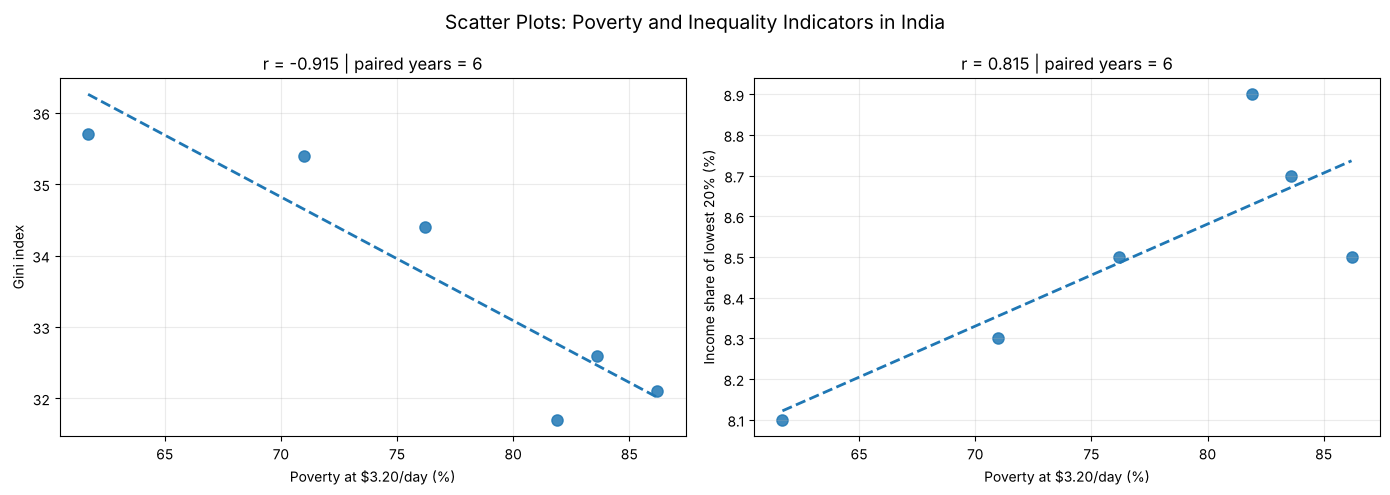

In [ ]:
# Plot two substantively relevant pairs using only matching years
scatter_pairs = [
    (selected_indicators[0], selected_indicators[2],
     "Poverty at $3.20/day (%)", "Gini index"),
    (selected_indicators[0], selected_indicators[3],
     "Poverty at $3.20/day (%)", "Income share of lowest 20% (%)")
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (x_indicator, y_indicator, x_label, y_label) in zip(axes, scatter_pairs):
    pair = indicator_wide[[x_indicator, y_indicator]].dropna()

    ax.scatter(pair[x_indicator], pair[y_indicator], s=65, alpha=0.85)

    if len(pair) >= 2 and pair[x_indicator].nunique() > 1:
        slope, intercept = np.polyfit(pair[x_indicator], pair[y_indicator], 1)
        x_line = np.linspace(pair[x_indicator].min(), pair[x_indicator].max(), 100)
        ax.plot(x_line, slope * x_line + intercept, linestyle="--", linewidth=2)

    r_value = pair[x_indicator].corr(pair[y_indicator]) if len(pair) >= 2 else np.nan
    ax.set_title(f"r = {r_value:.3f} | paired years = {len(pair)}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.25)

fig.suptitle("Scatter Plots: Poverty and Inequality Indicators in India", fontsize=14)
plt.tight_layout()
plt.show()

### 6.4 Linear Regression

**Regression** describes how the *mean* of one variable (the response $y$) changes with another (the predictor $x$). The regression line of $y$ on $x$ is $\hat{y} = a + b_{yx}x$, where

$$
\boxed{b_{yx} = \frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sum (x_i-\bar{x})^2} = r\,\frac{s_y}{s_x}}\qquad
\boxed{a = \bar{y} - b_{yx}\bar{x}}
$$

Likewise the regression of $x$ on $y$ has coefficient $b_{xy} = r\,s_x/s_y$. The two regression coefficients are linked to the correlation coefficient by

$$
\boxed{r^2 = b_{yx}\cdot b_{xy}}
$$

(both coefficients have the same sign as $r$). The **standard error of estimate** is $s_e=\sqrt{SSE/(n-2)}$ and the proportion of variation explained is $R^2=r^2$.

Here the regression is fitted on the **cross-country** data: the response is the *income share of the lowest 20%* and the predictor is the *Gini index*.

n = 163, r = -0.9351
Regression of Lowest-20% share on Gini : ŷ = 14.969 + (-0.2189)·Gini
Regression of Gini on Lowest-20% share : x̂ = 64.585 + (-3.9945)·Share
b_yx × b_xy = 0.8744   and   r² = 0.8744   (they are equal)
R² = 0.8744 | Standard error of estimate = 0.649
Slope = -0.2189, SE(slope) = 0.0065, t = -33.47, p = 2.03e-74

India: Gini = 35.7 -> predicted share of lowest 20% = 7.15%, actual = 8.1%, residual = +0.95


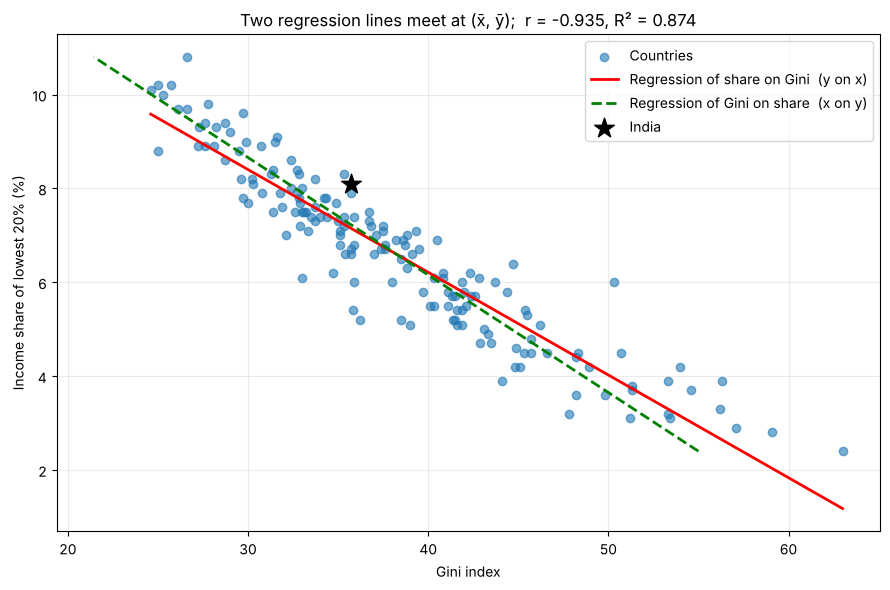

In [ ]:
reg = cross[["Gini", "Lowest 20% share"]].dropna()
x = reg["Gini"].values; y = reg["Lowest 20% share"].values
n = len(x)

Sxx = np.sum((x - x.mean()) ** 2); Syy = np.sum((y - y.mean()) ** 2)
Sxy = np.sum((x - x.mean()) * (y - y.mean()))
r = Sxy / np.sqrt(Sxx * Syy)

b_yx = Sxy / Sxx;  a_yx = y.mean() - b_yx * x.mean()     # regression of y on x
b_xy = Sxy / Syy;  a_xy = x.mean() - b_xy * y.mean()     # regression of x on y

print(f"n = {n}, r = {r:.4f}")
print(f"Regression of Lowest-20% share on Gini : ŷ = {a_yx:.3f} + ({b_yx:.4f})·Gini")
print(f"Regression of Gini on Lowest-20% share : x̂ = {a_xy:.3f} + ({b_xy:.4f})·Share")
print(f"b_yx × b_xy = {b_yx*b_xy:.4f}   and   r² = {r**2:.4f}   (they are equal)")

yhat = a_yx + b_yx * x
sse = np.sum((y - yhat) ** 2)
se_est = np.sqrt(sse / (n - 2))
se_slope = se_est / np.sqrt(Sxx)
t_slope = b_yx / se_slope
p_slope = 2 * stats.t.sf(abs(t_slope), n - 2)
print(f"R² = {r**2:.4f} | Standard error of estimate = {se_est:.3f}")
print(f"Slope = {b_yx:.4f}, SE(slope) = {se_slope:.4f}, t = {t_slope:.2f}, p = {p_slope:.2e}")

# Interpretation / prediction for India
g_ind, s_ind = india_cross["Gini"], india_cross["Lowest 20% share"]
pred = a_yx + b_yx * g_ind
print(f"\nIndia: Gini = {g_ind} -> predicted share of lowest 20% = {pred:.2f}%, actual = {s_ind}%, residual = {s_ind - pred:+.2f}")

# Plot both regression lines
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(x, y, alpha=0.6, label="Countries")
xx = np.linspace(x.min(), x.max(), 100)
ax.plot(xx, a_yx + b_yx * xx, color="red", linewidth=2, label="Regression of share on Gini  (y on x)")
yy = np.linspace(y.min(), y.max(), 100)
ax.plot(a_xy + b_xy * yy, yy, color="green", linestyle="--", linewidth=2, label="Regression of Gini on share  (x on y)")
ax.scatter(g_ind, s_ind, s=220, marker="*", color="black", zorder=5, label="India")
ax.set_xlabel("Gini index"); ax.set_ylabel("Income share of lowest 20% (%)")
ax.set_title(f"Two regression lines meet at (x̄, ȳ);  r = {r:.3f}, R² = {r**2:.3f}")
ax.legend(); plt.tight_layout(); plt.show()

### 6.5 Rank Correlation: Spearman vs Pearson

**Spearman's rank correlation coefficient** $\rho$ measures the strength of a **monotonic** relationship using only the *ranks* of the data, so it is less affected by outliers and by non-linearity than Pearson's $r$. When there are no tied ranks,

$$
\boxed{\rho = 1 - \frac{6\sum_{i=1}^{n} d_i^2}{n(n^2-1)}}
$$

where $d_i$ is the difference between the ranks of $x_i$ and $y_i$. With ties, tied values get the average of their ranks and $\rho$ is computed as the Pearson correlation of the ranks. Like $r$, $\rho \in [-1, 1]$.

**Worked example – India:** rank the Gini index against the $3.20/day poverty headcount for the six years in which both are available.

,Gini,Poverty $3.20 (%),Rank (Gini),Rank (Poverty),d,d²
Year,,,,,,
1983,32.1,86.2,2.0,6.0,-4.0,16.0
1987,32.6,83.6,3.0,5.0,-2.0,4.0
1993,31.7,81.9,1.0,4.0,-3.0,9.0
2004,34.4,76.2,4.0,3.0,1.0,1.0
2009,35.4,71.0,5.0,2.0,3.0,9.0
2011,35.7,61.7,6.0,1.0,5.0,25.0


Σd² = 64, n = 6
Spearman ρ (formula) = -0.8286 | Spearman ρ (SciPy) = -0.8286 | Pearson r = -0.9154


,Pair,n,Pearson r,p (Pearson),Spearman ρ,p (Spearman)
0,Gini vs Lowest 20% share,163,-0.9351,0.0000,-0.9435,0.0
1,Gini vs Poverty $3.20,164,0.4097,0.0000,0.5599,0.0
2,Poverty $3.20 vs Lowest 20% share,163,-0.3063,0.0001,-0.4407,0.0


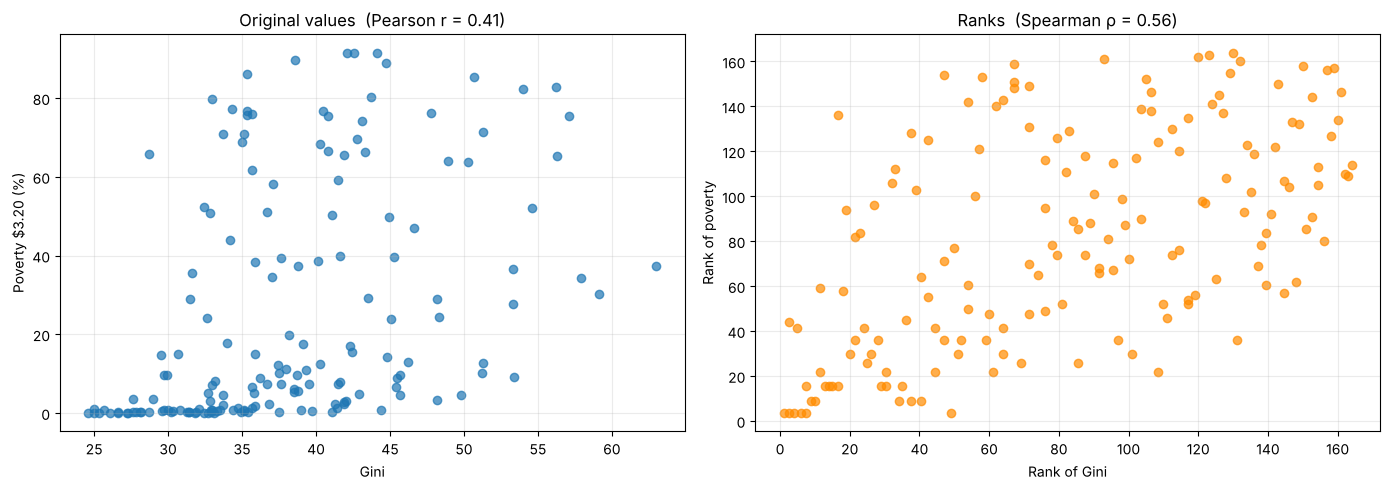

In [ ]:
# --- Worked example with the rank-difference formula (India, no ties) ---
pair = indicator_wide[[selected_indicators[2], selected_indicators[0]]].dropna()
pair.columns = ["Gini", "Poverty $3.20 (%)"]
pair["Rank (Gini)"] = pair["Gini"].rank()
pair["Rank (Poverty)"] = pair["Poverty $3.20 (%)"].rank()
pair["d"] = pair["Rank (Gini)"] - pair["Rank (Poverty)"]
pair["d²"] = pair["d"] ** 2
display(pair)

n = len(pair)
rho_manual = 1 - 6 * pair["d²"].sum() / (n * (n ** 2 - 1))
rho_scipy, p_scipy = stats.spearmanr(pair["Gini"], pair["Poverty $3.20 (%)"])
r_pearson = pair["Gini"].corr(pair["Poverty $3.20 (%)"])
print(f"Σd² = {pair['d²'].sum():.0f}, n = {n}")
print(f"Spearman ρ (formula) = {rho_manual:.4f} | Spearman ρ (SciPy) = {rho_scipy:.4f} | Pearson r = {r_pearson:.4f}")

# --- Cross-country comparison of Pearson and Spearman (ties handled by average ranks) ---
rows = []
for a, b in [("Gini", "Lowest 20% share"), ("Gini", "Poverty $3.20"), ("Poverty $3.20", "Lowest 20% share")]:
    sub = cross[[a, b]].dropna()
    r_p, p_p = stats.pearsonr(sub[a], sub[b])
    r_s, p_s = stats.spearmanr(sub[a], sub[b])
    rows.append({"Pair": f"{a} vs {b}", "n": len(sub), "Pearson r": r_p, "p (Pearson)": p_p,
                 "Spearman ρ": r_s, "p (Spearman)": p_s})
display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sub = cross[["Gini", "Poverty $3.20"]].dropna()
axes[0].scatter(sub["Gini"], sub["Poverty $3.20"], alpha=0.7)
axes[0].set_title(f"Original values  (Pearson r = {sub.corr().iloc[0,1]:.2f})")
axes[0].set_xlabel("Gini"); axes[0].set_ylabel("Poverty $3.20 (%)")
axes[1].scatter(sub["Gini"].rank(), sub["Poverty $3.20"].rank(), alpha=0.7, color="darkorange")
axes[1].set_title(f"Ranks  (Spearman ρ = {sub.corr(method='spearman').iloc[0,1]:.2f})")
axes[1].set_xlabel("Rank of Gini"); axes[1].set_ylabel("Rank of poverty")
plt.tight_layout(); plt.show()

## 7. Sampling Distributions, Confidence Intervals and Z-Tests

### 7.1 Sampling Distribution of the Mean and Standard Error

The **sampling distribution** of a statistic is the distribution of its values over all possible samples of the same size drawn from the population. For the sample mean $\bar{X}$ of size $n$ from a population with mean $\mu$ and standard deviation $\sigma$:

$$
\boxed{E(\bar{X}) = \mu}\qquad
\boxed{SE(\bar{X}) = \sigma_{\bar{X}} = \frac{\sigma}{\sqrt{n}}}\qquad
\left(\text{estimated by } \frac{s}{\sqrt{n}}\right)
$$

For a sample proportion: $SE(\hat{p}) = \sqrt{\dfrac{p(1-p)}{n}}$. The **standard error** (SE) is the standard deviation of a statistic; it shrinks as $\sqrt{n}$ grows, which is why larger samples give more precise estimates.

### 7.2 Central Limit Theorem (CLT)

> **CLT:** If $X_1,\dots,X_n$ are independent observations from *any* population with mean $\mu$ and finite variance $\sigma^2$, then for large $n$ the distribution of $\bar{X}$ is approximately normal, $\bar{X}\approx N\!\left(\mu,\ \sigma^2/n\right)$, i.e. $Z=\dfrac{\bar{X}-\mu}{\sigma/\sqrt{n}}\approx N(0,1)$.

**Simulation:** the population is the cross-country **poverty headcount at $3.20/day**, which is far from normal (very skewed / bimodal). 5,000 random samples are drawn for each sample size $n$ and the sample means are plotted.

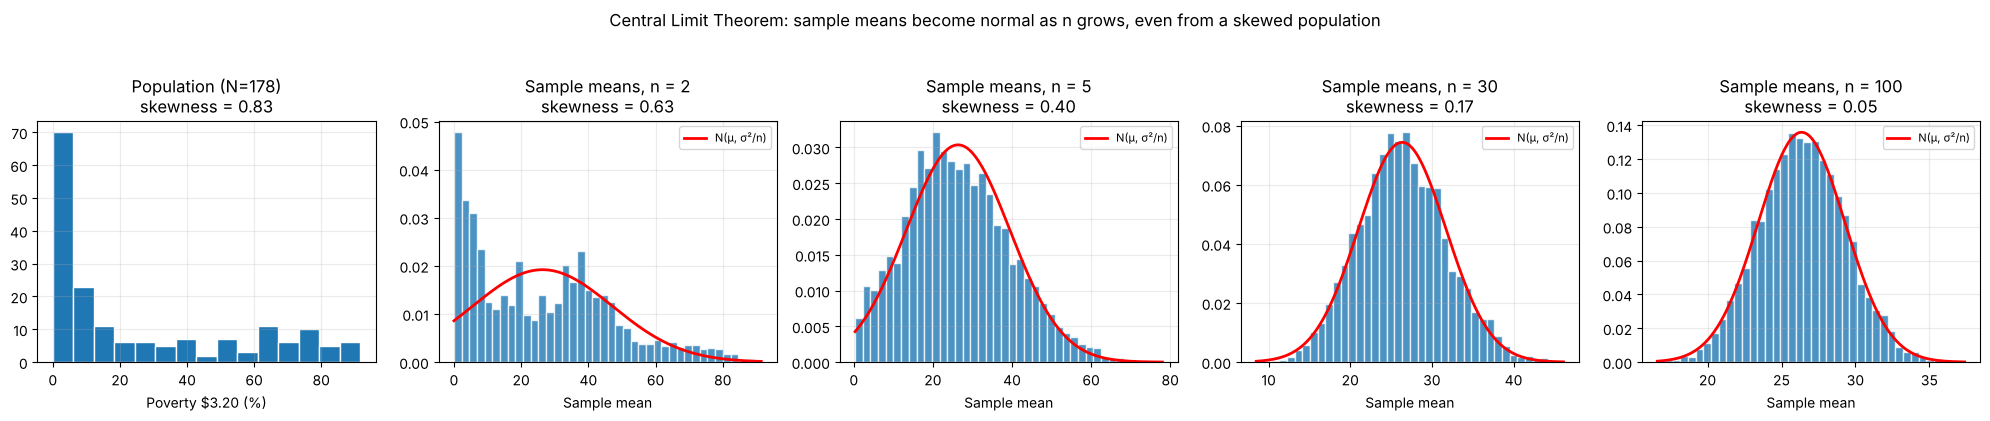

Population mean μ = 26.36, population SD σ = 29.37


,n,Mean of x̄ (≈ μ),Empirical SD of x̄,Theoretical SE = σ/√n,Skewness of x̄
0,2,26.155,20.904,20.771,0.635
1,5,26.440,13.168,13.136,0.400
2,30,26.376,5.387,5.363,0.167
3,100,26.403,2.931,2.937,0.050


In [ ]:
rng = np.random.default_rng(2024)
pop = pov320_pop.values
mu_pop, sigma_pop = pop.mean(), pop.std(ddof=0)
sizes = [2, 5, 30, 100]
reps = 5000

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].hist(pop, bins=15, edgecolor="white")
axes[0].set_title(f"Population (N={len(pop)})\nskewness = {stats.skew(pop):.2f}")
axes[0].set_xlabel("Poverty $3.20 (%)")

rows = []
for ax, n in zip(axes[1:], sizes):
    means = rng.choice(pop, size=(reps, n), replace=True).mean(axis=1)
    ax.hist(means, bins=40, density=True, edgecolor="white", alpha=0.8)
    xs = np.linspace(means.min(), means.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu_pop, sigma_pop / np.sqrt(n)), "r-", linewidth=2, label="N(μ, σ²/n)")
    ax.set_title(f"Sample means, n = {n}\nskewness = {stats.skew(means):.2f}")
    ax.set_xlabel("Sample mean"); ax.legend(fontsize=8)
    rows.append({"n": n, "Mean of x̄ (≈ μ)": means.mean(), "Empirical SD of x̄": means.std(ddof=1),
                 "Theoretical SE = σ/√n": sigma_pop / np.sqrt(n), "Skewness of x̄": stats.skew(means)})
plt.suptitle("Central Limit Theorem: sample means become normal as n grows, even from a skewed population", y=1.04)
plt.tight_layout(); plt.show()

print(f"Population mean μ = {mu_pop:.2f}, population SD σ = {sigma_pop:.2f}")
display(pd.DataFrame(rows).round(3))

### 7.3 Confidence Intervals

A **confidence interval** (CI) gives a range of plausible values for a parameter. A $100(1-\alpha)\%$ CI is built so that, over repeated sampling, $100(1-\alpha)\%$ of such intervals contain the true parameter.

| Parameter | Condition | Confidence interval |
|---|---|---|
| Mean $\mu$ | $\sigma$ known or $n$ large | $\bar{x} \pm z_{\alpha/2}\,\dfrac{\sigma}{\sqrt{n}}$ |
| Mean $\mu$ | $\sigma$ unknown, small $n$ | $\bar{x} \pm t_{\alpha/2,\,n-1}\,\dfrac{s}{\sqrt{n}}$ |
| Proportion $p$ | large $n$ | $\hat{p} \pm z_{\alpha/2}\sqrt{\dfrac{\hat{p}(1-\hat{p})}{n}}$ |

The term after $\pm$ is the **margin of error** $E = (\text{critical value}) \times SE$. Its width increases with the confidence level and decreases with $\sqrt{n}$. The required sample size for a mean is $n = \left(\dfrac{z_{\alpha/2}\,\sigma}{E}\right)^2$.

**Important:** a 95% CI does *not* mean there is a 95% probability that $\mu$ lies in this particular interval; $\mu$ is fixed and the *procedure* captures it 95% of the time.

In [ ]:
def mean_ci(x, conf=0.95, sigma=None):
    x = np.asarray(x, float); n = len(x); xbar = x.mean()
    if sigma is not None:                                  # z-interval, known sigma
        se = sigma / np.sqrt(n); crit = stats.norm.ppf(1 - (1 - conf) / 2)
    else:                                                  # t-interval, estimated sigma
        se = x.std(ddof=1) / np.sqrt(n); crit = stats.t.ppf(1 - (1 - conf) / 2, n - 1)
    return xbar, se, crit, xbar - crit * se, xbar + crit * se

rows = []
# (a) All countries, Gini: z-interval (sigma = population SD treated as known) and t-interval
xbar, se, crit, lo, hi = mean_ci(gini_pop, sigma=gini_pop.std(ddof=1))
rows.append(["Mean Gini, all countries (z)", len(gini_pop), xbar, se, crit, lo, hi])
xbar, se, crit, lo, hi = mean_ci(gini_pop)
rows.append(["Mean Gini, all countries (t)", len(gini_pop), xbar, se, crit, lo, hi])
# (b) Random sample of 30 countries
xbar, se, crit, lo, hi = mean_ci(sample30)
rows.append(["Mean Gini, random sample n=30 (t)", 30, xbar, se, crit, lo, hi])
# (c) India's six survey years: small sample -> t-interval
india_gini = indicator_wide[selected_indicators[2]].dropna()
xbar, se, crit, lo, hi = mean_ci(india_gini)
rows.append(["India's mean Gini, 6 survey years (t)", len(india_gini), xbar, se, crit, lo, hi])
display(pd.DataFrame(rows, columns=["Interval", "n", "Mean", "SE", "Critical value", "Lower", "Upper"]).round(3))

# (d) CI for a proportion: share of countries with high inequality (Gini > 40)
n_p = len(gini_pop); x_high = int((gini_pop > 40).sum()); p_hat = x_high / n_p
se_p = np.sqrt(p_hat * (1 - p_hat) / n_p); zc = stats.norm.ppf(0.975)
print(f"Proportion of countries with Gini > 40: {x_high}/{n_p} = {p_hat:.3f}")
print(f"95% CI for p: ({p_hat - zc*se_p:.3f}, {p_hat + zc*se_p:.3f})   [SE = {se_p:.4f}]")

# (e) Effect of confidence level and sample size on the margin of error
s = gini_pop.std(ddof=1)
effect = pd.DataFrame({
    "Confidence": ["90%", "95%", "99%"],
    "z critical": [stats.norm.ppf(0.95), stats.norm.ppf(0.975), stats.norm.ppf(0.995)],
})
for n_ in [10, 30, 100, 164]:
    effect[f"Margin of error (n={n_})"] = effect["z critical"] * s / np.sqrt(n_)
display(effect.round(3))

E = 1.0
n_req = int(np.ceil((stats.norm.ppf(0.975) * s / E) ** 2))
print(f"Sample size needed to estimate mean Gini within ±{E} at 95% confidence: n ≥ {n_req}")

,Interval,n,Mean,SE,Critical value,Lower,Upper
0,"Mean Gini, all countries (z)",164,38.268,0.618,1.960,37.056,39.480
1,"Mean Gini, all countries (t)",164,38.268,0.618,1.975,37.047,39.489
2,"Mean Gini, random sample n=30 (t)",30,41.040,1.473,2.045,38.027,44.053
3,"India's mean Gini, 6 survey years (t)",6,33.650,0.710,2.571,31.824,35.476


Proportion of countries with Gini > 40: 63/164 = 0.384
95% CI for p: (0.310, 0.459)   [SE = 0.0380]


,Confidence,z critical,Margin of error (n=10),Margin of error (n=30),Margin of error (n=100),Margin of error (n=164)
0,90%,1.645,4.119,2.378,1.303,1.017
1,95%,1.960,4.908,2.834,1.552,1.212
2,99%,2.576,6.450,3.724,2.040,1.593


Sample size needed to estimate mean Gini within ±1.0 at 95% confidence: n ≥ 241


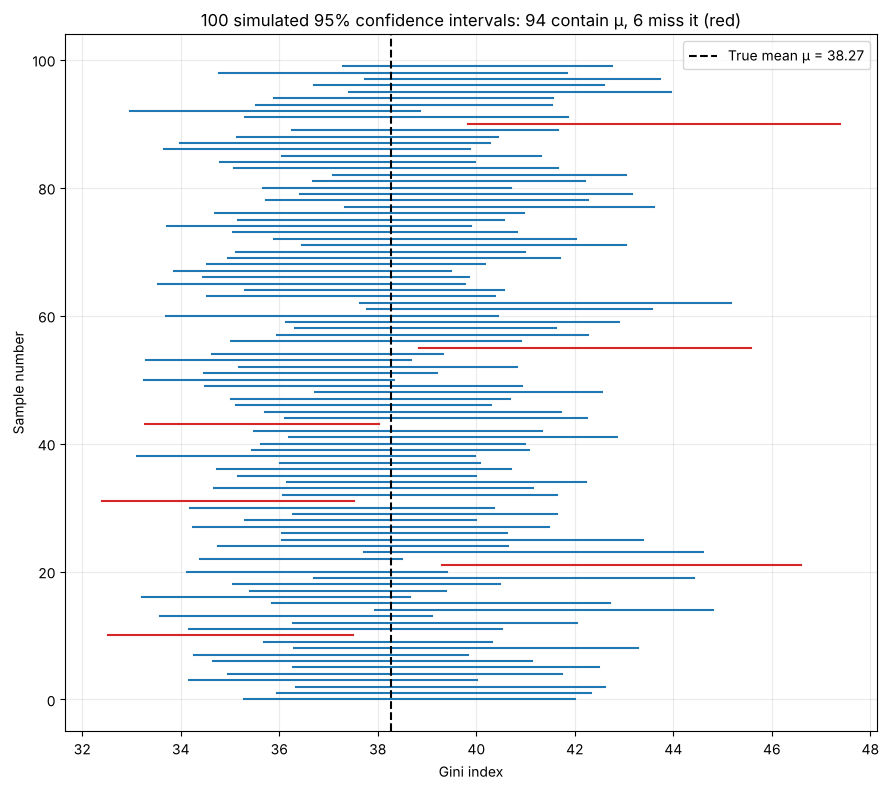

In [ ]:
# Simulation: what does "95% confidence" mean?  Draw 100 samples (n = 30) from the population
rng = np.random.default_rng(7)
mu = gini_pop.mean()
fig, ax = plt.subplots(figsize=(9, 8))
miss = 0
for i in range(100):
    smp = rng.choice(gini_pop.values, size=30, replace=True)
    xbar, se, crit, lo, hi = mean_ci(smp)
    ok = lo <= mu <= hi
    miss += (not ok)
    ax.plot([lo, hi], [i, i], color="tab:blue" if ok else "tab:red", linewidth=1.5)
ax.axvline(mu, color="black", linestyle="--", label=f"True mean μ = {mu:.2f}")
ax.set_xlabel("Gini index"); ax.set_ylabel("Sample number")
ax.set_title(f"100 simulated 95% confidence intervals: {100-miss} contain μ, {miss} miss it (red)")
ax.legend(); plt.tight_layout(); plt.show()

### 7.4 Hypothesis Testing Framework, Type-I and Type-II Errors

**Steps of a test of hypothesis**

1. State the **null hypothesis** $H_0$ (the status quo / no-effect claim) and the **alternative hypothesis** $H_1$.
2. Choose the **level of significance** $\alpha$ (here $\alpha = 0.05$).
3. Choose the test statistic and find the critical region (or the $p$-value).
4. Compute the statistic from the sample.
5. **Decision:** reject $H_0$ if the statistic lies in the critical region, i.e. if $p\text{-value} < \alpha$; otherwise *fail to reject* $H_0$.

**Errors in testing**

| | $H_0$ is true | $H_0$ is false |
|---|---|---|
| **Reject $H_0$** | **Type-I error** (probability $\alpha$, the level of significance) | Correct decision (probability $1-\beta$ = **power**) |
| **Do not reject $H_0$** | Correct decision (probability $1-\alpha$) | **Type-II error** (probability $\beta$) |

$$
\alpha = P(\text{reject } H_0 \mid H_0 \text{ true}),\qquad \beta = P(\text{fail to reject } H_0 \mid H_0 \text{ false}),\qquad \text{Power} = 1-\beta
$$

For a fixed sample size, decreasing $\alpha$ increases $\beta$; both can be reduced only by increasing $n$.

**One-tailed vs two-tailed tests**

| Test | $H_1$ | Critical region (Z-test) | $p$-value |
|---|---|---|---|
| Two-tailed | $\mu \neq \mu_0$ | $\lvert Z\rvert > z_{\alpha/2}$ (±1.96 at 5%) | $2\,P(Z > \lvert z\rvert)$ |
| Right-tailed | $\mu > \mu_0$ | $Z > z_\alpha$ (1.645 at 5%) | $P(Z > z)$ |
| Left-tailed | $\mu < \mu_0$ | $Z < -z_\alpha$ (−1.645 at 5%) | $P(Z < z)$ |

Use a one-tailed test only when the direction of the effect is specified *before* looking at the data.

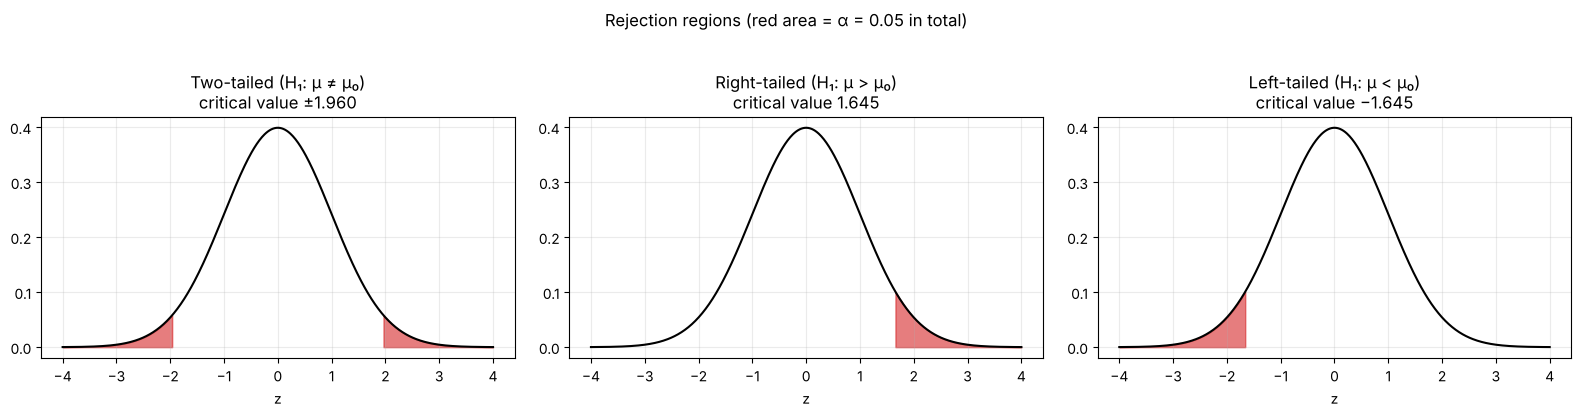

In [ ]:
# Visualise the critical regions at alpha = 0.05
alpha = 0.05
xs = np.linspace(-4, 4, 500)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

zc2 = stats.norm.ppf(1 - alpha / 2); zc1 = stats.norm.ppf(1 - alpha)
cfg = [("Two-tailed (H₁: μ ≠ μ₀)", [(-4, -zc2), (zc2, 4)], f"±{zc2:.3f}"),
       ("Right-tailed (H₁: μ > μ₀)", [(zc1, 4)], f"{zc1:.3f}"),
       ("Left-tailed (H₁: μ < μ₀)", [(-4, -zc1)], f"−{zc1:.3f}")]
for ax, (title, regions, crit) in zip(axes, cfg):
    ax.plot(xs, stats.norm.pdf(xs), "k")
    for lo, hi in regions:
        m = (xs >= lo) & (xs <= hi)
        ax.fill_between(xs[m], stats.norm.pdf(xs[m]), color="tab:red", alpha=0.6)
    ax.set_title(f"{title}\ncritical value {crit}"); ax.set_xlabel("z")
fig.suptitle("Rejection regions (red area = α = 0.05 in total)", y=1.03)
plt.tight_layout(); plt.show()

### 7.5 Z-Test for a Single Mean

When the population standard deviation $\sigma$ is known (or $n$ is large), the test statistic for $H_0:\mu=\mu_0$ is

$$
\boxed{Z = \frac{\bar{x} - \mu_0}{\sigma/\sqrt{n}}} \sim N(0,1)\ \text{under } H_0
$$

**Problem.** A Gini index above **40** is commonly cited as a warning level for high income inequality. Do **Sub-Saharan African** countries have a mean Gini different from (and, specifically, greater than) 40?

- Sample: the Sub-Saharan African countries with a Gini estimate ($n$ is large, so the Z-test applies).
- $\sigma$: taken as the standard deviation of the Gini index over *all* countries (treated as known).
- $H_0:\ \mu = 40$ against **(a)** $H_1:\ \mu \neq 40$ (two-tailed) and **(b)** $H_1:\ \mu > 40$ (right-tailed). $\alpha = 0.05$.

n = 45, sample mean = 43.564, σ (known) = 7.895, SE = 1.177
Z = (43.564 − 40.0) / 1.177 = 3.029

(a) Two-tailed  : critical values ±1.960,  p-value = 0.00246  -> Reject H0
(b) Right-tailed: critical value  1.645,  p-value = 0.00123  -> Reject H0
95% CI for the mean Gini of Sub-Saharan Africa: (41.26, 45.87)  -> 40 is outside the interval


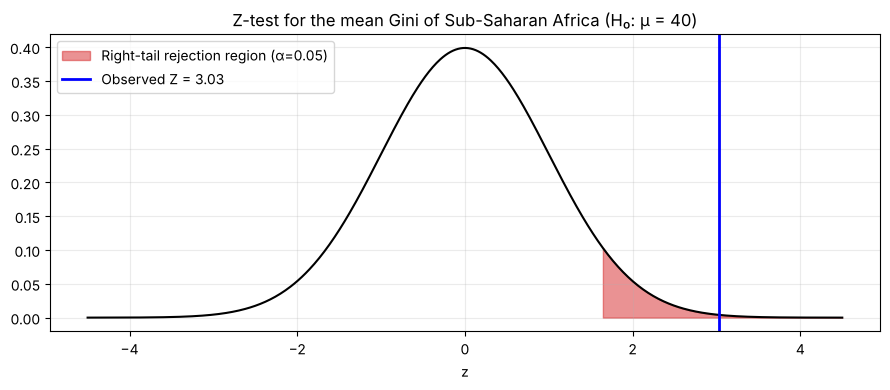

In [ ]:
test_log = []          # collects every hypothesis test for the summary table in Section 8.7

def log_test(name, h0, h1, stat_name, stat, df, p_value, alpha=0.05):
    test_log.append({"Test": name, "H0": h0, "H1": h1, "Statistic": f"{stat_name} = {stat:.3f}",
                     "df": df, "p-value": p_value, "α": alpha,
                     "Decision": "Reject H0" if p_value < alpha else "Fail to reject H0"})

# ---------- Z-test for a single mean ----------
ssa = cross.loc[cross["Region"] == "Sub-Saharan Africa", "Gini"].dropna()
mu0 = 40.0
sigma_known = gini_pop.std(ddof=0)             # population SD of Gini over all countries
n_s = len(ssa); xbar_s = ssa.mean()
se_z = sigma_known / np.sqrt(n_s)
z_stat = (xbar_s - mu0) / se_z

alpha = 0.05
p_two = 2 * stats.norm.sf(abs(z_stat))
p_right = stats.norm.sf(z_stat)
zc_two, zc_right = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(1 - alpha)

print(f"n = {n_s}, sample mean = {xbar_s:.3f}, σ (known) = {sigma_known:.3f}, SE = {se_z:.3f}")
print(f"Z = ({xbar_s:.3f} − {mu0}) / {se_z:.3f} = {z_stat:.3f}\n")
print(f"(a) Two-tailed  : critical values ±{zc_two:.3f},  p-value = {p_two:.5f}  -> {'Reject H0' if p_two < alpha else 'Fail to reject H0'}")
print(f"(b) Right-tailed: critical value  {zc_right:.3f},  p-value = {p_right:.5f}  -> {'Reject H0' if p_right < alpha else 'Fail to reject H0'}")
ci_lo, ci_hi = xbar_s - zc_two * se_z, xbar_s + zc_two * se_z
print(f"95% CI for the mean Gini of Sub-Saharan Africa: ({ci_lo:.2f}, {ci_hi:.2f})  -> 40 is {'outside' if not ci_lo <= 40 <= ci_hi else 'inside'} the interval")

log_test("Z-test, single mean (two-tailed)", "μ(SSA Gini) = 40", "μ ≠ 40", "Z", z_stat, "–", p_two)
log_test("Z-test, single mean (right-tailed)", "μ(SSA Gini) = 40", "μ > 40", "Z", z_stat, "–", p_right)

# Plot the test statistic against the null distribution
xs = np.linspace(-4.5, max(4.5, z_stat + 1), 600)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(xs, stats.norm.pdf(xs), "k")
ax.fill_between(xs[xs >= zc_right], stats.norm.pdf(xs[xs >= zc_right]), color="tab:red", alpha=0.5, label="Right-tail rejection region (α=0.05)")
ax.axvline(z_stat, color="blue", linewidth=2, label=f"Observed Z = {z_stat:.2f}")
ax.set_xlabel("z"); ax.set_title("Z-test for the mean Gini of Sub-Saharan Africa (H₀: μ = 40)"); ax.legend()
plt.tight_layout(); plt.show()

### 7.6 Z-Test for a Single Proportion

For $H_0: p = p_0$ the test statistic (large $n$, with $np_0 \ge 5$ and $n(1-p_0)\ge 5$) is

$$
\boxed{Z = \frac{\hat{p} - p_0}{\sqrt{\dfrac{p_0(1-p_0)}{n}}}} \sim N(0,1)\ \text{under } H_0
$$

Note that the standard error uses $p_0$ (the hypothesised value), not $\hat{p}$.

**Problem.** Is the proportion of countries with **high inequality (Gini > 40)** different from one half? Test it for **(a)** the **Sub-Saharan African** countries and **(b)** all countries, with $H_0: p = 0.5$ and $\alpha = 0.05$ (two-tailed).

In [ ]:
def z_test_proportion(successes, n, p0, alternative="two-sided"):
    p_hat = successes / n
    se0 = np.sqrt(p0 * (1 - p0) / n)
    z = (p_hat - p0) / se0
    if alternative == "two-sided":  p = 2 * stats.norm.sf(abs(z))
    elif alternative == "greater":  p = stats.norm.sf(z)
    else:                           p = stats.norm.cdf(z)
    return p_hat, se0, z, p

p0 = 0.5
rows = []
for label, vals in [("Sub-Saharan Africa", ssa), ("All countries", gini_pop)]:
    n_ = len(vals); x_ = int((vals > 40).sum())
    assert n_ * p0 >= 5 and n_ * (1 - p0) >= 5          # large-sample condition
    p_hat, se0, z, p = z_test_proportion(x_, n_, p0)
    rows.append({"Group": label, "n": n_, "High-inequality countries": x_, "p̂": p_hat,
                 "SE under H0": se0, "Z": z, "p-value (two-tailed)": p,
                 "Decision (α=0.05)": "Reject H0" if p < 0.05 else "Fail to reject H0"})
    log_test(f"Z-test, single proportion ({label})", "p = 0.5", "p ≠ 0.5", "Z", z, "–", p)
display(pd.DataFrame(rows).round(4))

# One-tailed version for Sub-Saharan Africa (H1: p > 0.5)
n_ = len(ssa); x_ = int((ssa > 40).sum())
_, _, z1, p1 = z_test_proportion(x_, n_, p0, "greater")
print(f"Sub-Saharan Africa, right-tailed (H1: p > 0.5): Z = {z1:.3f}, p-value = {p1:.4f} -> "
      f"{'Reject H0' if p1 < 0.05 else 'Fail to reject H0'}")

,Group,n,High-inequality countries,p̂,SE under H0,Z,p-value (two-tailed),Decision (α=0.05)
0,Sub-Saharan Africa,45,30,0.6667,0.0745,2.2361,0.0253,Reject H0
1,All countries,164,63,0.3841,0.0390,-2.9673,0.0030,Reject H0


Sub-Saharan Africa, right-tailed (H1: p > 0.5): Z = 2.236, p-value = 0.0127 -> Reject H0


### 7.7 Type-I Error, Type-II Error and Power of the Z-Test (illustration)

For the right-tailed test of Section 7.5 ($H_0:\mu=40$, $\sigma$ known, $n = n_{SSA}$), the test rejects when $\bar{x} > x_c$, where the critical sample mean is

$$
x_c = \mu_0 + z_{\alpha}\frac{\sigma}{\sqrt{n}}.
$$

If the true mean is actually $\mu_1 > \mu_0$, then

$$
\boxed{\beta(\mu_1) = P(\bar{X} \le x_c \mid \mu=\mu_1) = \Phi\!\left(\frac{x_c-\mu_1}{\sigma/\sqrt{n}}\right)},\qquad \text{Power} = 1-\beta .
$$

The probability of a Type-I error is fixed at $\alpha$ by construction; $\beta$ depends on how far the true mean is from $\mu_0$ and on $n$. A **simulation** below verifies both numbers.

n = 45, σ = 7.89, SE = 1.177, critical sample mean x_c = 41.936


,True mean μ₁,β (Type-II error),Power = 1 − β
0,40.5,0.8888,0.1112
1,41.0,0.7867,0.2133
2,42.0,0.4782,0.5218
3,43.0,0.1829,0.8171
4,44.0,0.0397,0.9603
5,45.0,0.0046,0.9954


Simulated Type-I error rate (μ = 40):   0.0487   (theory: 0.05)
Simulated power at μ₁ = 42:            0.5233   (theory: 0.5218)


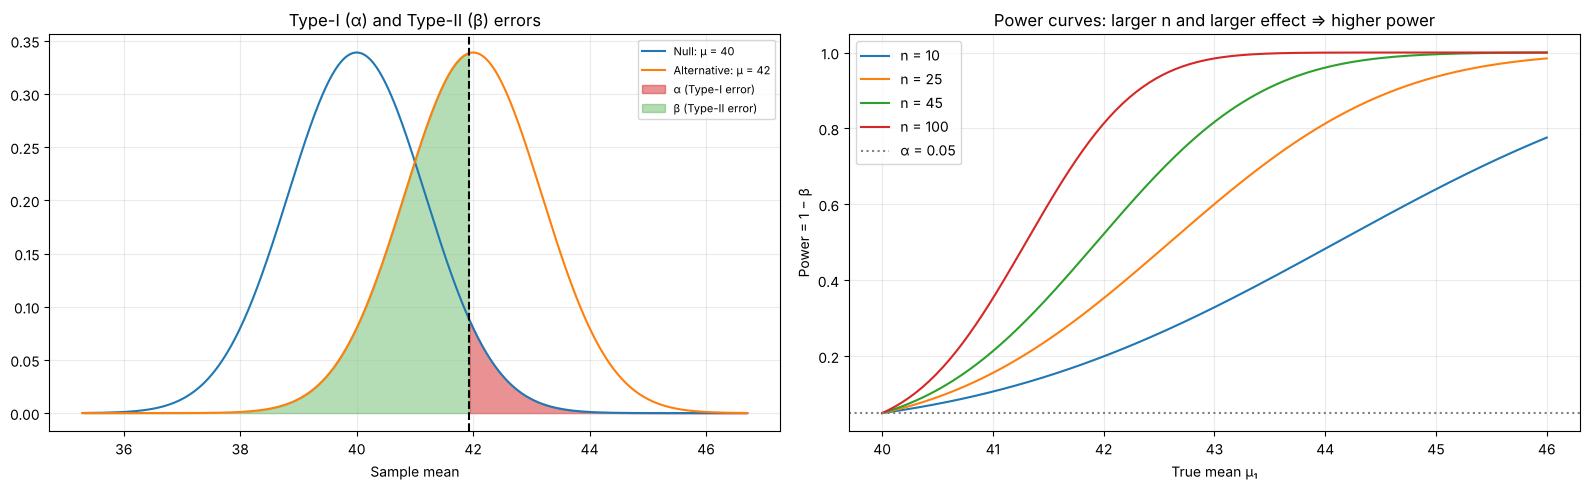

In [ ]:
n_ = n_s; sigma = sigma_known; mu0 = 40.0; alpha = 0.05
se = sigma / np.sqrt(n_)
x_crit = mu0 + stats.norm.ppf(1 - alpha) * se
print(f"n = {n_}, σ = {sigma:.2f}, SE = {se:.3f}, critical sample mean x_c = {x_crit:.3f}")

mu1_values = [40.5, 41, 42, 43, 44, 45]
power_table = pd.DataFrame({"True mean μ₁": mu1_values})
power_table["β (Type-II error)"] = stats.norm.cdf((x_crit - power_table["True mean μ₁"]) / se)
power_table["Power = 1 − β"] = 1 - power_table["β (Type-II error)"]
display(power_table.round(4))

# Monte-Carlo check of alpha and power
rng = np.random.default_rng(11)
reps = 50000
sim_h0 = rng.normal(mu0, sigma, (reps, n_)).mean(axis=1)
sim_h1 = rng.normal(42, sigma, (reps, n_)).mean(axis=1)
print(f"Simulated Type-I error rate (μ = 40):   {np.mean(sim_h0 > x_crit):.4f}   (theory: {alpha})")
print(f"Simulated power at μ₁ = 42:            {np.mean(sim_h1 > x_crit):.4f}   (theory: {power_table.loc[2, 'Power = 1 − β']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
# (a) alpha and beta regions
mu1 = 42
xs = np.linspace(mu0 - 4 * se, mu1 + 4 * se, 600)
axes[0].plot(xs, stats.norm.pdf(xs, mu0, se), label="Null: μ = 40")
axes[0].plot(xs, stats.norm.pdf(xs, mu1, se), label=f"Alternative: μ = {mu1}")
m = xs >= x_crit
axes[0].fill_between(xs[m], stats.norm.pdf(xs[m], mu0, se), color="tab:red", alpha=0.5, label="α (Type-I error)")
m = xs <= x_crit
axes[0].fill_between(xs[m], stats.norm.pdf(xs[m], mu1, se), color="tab:green", alpha=0.35, label="β (Type-II error)")
axes[0].axvline(x_crit, color="k", linestyle="--")
axes[0].set_xlabel("Sample mean"); axes[0].set_title("Type-I (α) and Type-II (β) errors"); axes[0].legend(fontsize=8)

# (b) power curves for different sample sizes
mu_grid = np.linspace(40, 46, 200)
for nn in [10, 25, n_, 100]:
    s_e = sigma / np.sqrt(nn); xc = mu0 + stats.norm.ppf(1 - alpha) * s_e
    axes[1].plot(mu_grid, 1 - stats.norm.cdf((xc - mu_grid) / s_e), label=f"n = {nn}")
axes[1].axhline(alpha, color="grey", linestyle=":", label="α = 0.05")
axes[1].set_xlabel("True mean μ₁"); axes[1].set_ylabel("Power = 1 − β")
axes[1].set_title("Power curves: larger n and larger effect ⇒ higher power"); axes[1].legend()
plt.tight_layout(); plt.show()

## 8. Student's t-Tests and Chi-Square Tests

### 8.1 Null and Alternative Hypotheses (recap)

The **null hypothesis** $H_0$ states that there is *no effect / no difference / no association* (the sample result is due to chance); the **alternative hypothesis** $H_1$ states the effect that the investigator wants to establish. A test never "proves" $H_0$: it either **rejects** $H_0$ (the sample gives sufficient evidence for $H_1$) or **fails to reject** it (insufficient evidence). Every test in this section is run at $\alpha = 0.05$ and logged in a summary table at the end (Section 8.7).

### 8.2 Student's t-Test for a Single Mean

When $\sigma$ is **unknown** and the sample is small, the test statistic for $H_0:\mu=\mu_0$ is

$$
\boxed{t = \frac{\bar{x}-\mu_0}{s/\sqrt{n}}}\ \sim\ t_{(n-1)}\ \text{under } H_0,\qquad \text{degrees of freedom } \nu = n-1
$$

The $t$-distribution is bell-shaped like the normal but has heavier tails; it approaches $N(0,1)$ as $\nu\to\infty$. The test assumes the data come from an (approximately) normal population.

**Problem.** The **South Asian** countries form a small sample ($n$ < 10). Is their mean Gini index different from the **global mean Gini** of all countries? $H_0:\mu_{\text{South Asia}} = \mu_{\text{world}}$, $H_1:\mu_{\text{South Asia}} \neq \mu_{\text{world}}$ ($\alpha = 0.05$).

South Asian countries in the sample: Bangladesh, Bhutan, India, Sri Lanka, Maldives, Nepal, Pakistan
n = 7, mean = 34.357, s = 3.128, SE = 1.182, μ0 (global mean) = 38.268
t = (34.357 − 38.268) / 1.182 = -3.308  with df = 6
Critical values (two-tailed, 5%): ±2.447;  p-value = 0.0162  -> Reject H0
95% CI for the mean Gini of South Asia: (31.46, 37.25)
SciPy ttest_1samp: t = -3.308, p = 0.0162
Shapiro–Wilk normality check: p = 0.250  (p > 0.05 => no evidence against normality)


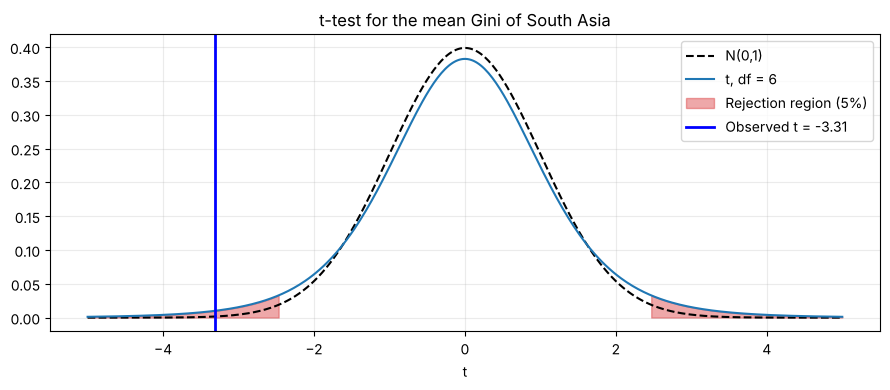

In [ ]:
south_asia = cross.loc[cross["Region"] == "South Asia", ["Short Name", "Gini"]].dropna()
x = south_asia["Gini"].values
mu0 = gini_pop.mean()                       # benchmark = global mean Gini
n = len(x); xbar = x.mean(); s = x.std(ddof=1)
se = s / np.sqrt(n); df = n - 1
t_stat = (xbar - mu0) / se
p_val = 2 * stats.t.sf(abs(t_stat), df)
t_crit = stats.t.ppf(0.975, df)

print("South Asian countries in the sample:", ", ".join(south_asia["Short Name"]))
print(f"n = {n}, mean = {xbar:.3f}, s = {s:.3f}, SE = {se:.3f}, μ0 (global mean) = {mu0:.3f}")
print(f"t = ({xbar:.3f} − {mu0:.3f}) / {se:.3f} = {t_stat:.3f}  with df = {df}")
print(f"Critical values (two-tailed, 5%): ±{t_crit:.3f};  p-value = {p_val:.4f}  -> {'Reject H0' if p_val < 0.05 else 'Fail to reject H0'}")
print(f"95% CI for the mean Gini of South Asia: ({xbar - t_crit*se:.2f}, {xbar + t_crit*se:.2f})")

# Cross-check with SciPy and with a quick normality check (small sample)
t_sp, p_sp = stats.ttest_1samp(x, mu0)
print(f"SciPy ttest_1samp: t = {t_sp:.3f}, p = {p_sp:.4f}")
print(f"Shapiro–Wilk normality check: p = {stats.shapiro(x).pvalue:.3f}  (p > 0.05 => no evidence against normality)")
log_test("t-test, single mean (South Asia Gini)", "μ = global mean Gini", "μ ≠ global mean", "t", t_stat, df, p_val)

# Compare t and normal distributions
xs = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(xs, stats.norm.pdf(xs), "k--", label="N(0,1)")
ax.plot(xs, stats.t.pdf(xs, df), label=f"t, df = {df}")
ax.fill_between(xs[xs <= -t_crit], stats.t.pdf(xs[xs <= -t_crit], df), color="tab:red", alpha=0.4)
ax.fill_between(xs[xs >= t_crit], stats.t.pdf(xs[xs >= t_crit], df), color="tab:red", alpha=0.4, label="Rejection region (5%)")
ax.axvline(t_stat, color="blue", linewidth=2, label=f"Observed t = {t_stat:.2f}")
ax.set_xlabel("t"); ax.set_title("t-test for the mean Gini of South Asia"); ax.legend()
plt.tight_layout(); plt.show()

### 8.3 Student's t-Test for the Difference Between Two Means

To compare the means of two **independent** samples, test $H_0:\mu_1-\mu_2=0$.

**Pooled (equal-variance) t-test**

$$
\boxed{t = \frac{\bar{x}_1-\bar{x}_2}{s_p\sqrt{\dfrac{1}{n_1}+\dfrac{1}{n_2}}}},\qquad
s_p^2 = \frac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2},\qquad \nu = n_1+n_2-2
$$

**Welch's t-test** (does not assume equal variances)

$$
t = \frac{\bar{x}_1-\bar{x}_2}{\sqrt{\dfrac{s_1^2}{n_1}+\dfrac{s_2^2}{n_2}}},\qquad
\nu \approx \frac{\left(\dfrac{s_1^2}{n_1}+\dfrac{s_2^2}{n_2}\right)^2}{\dfrac{(s_1^2/n_1)^2}{n_1-1}+\dfrac{(s_2^2/n_2)^2}{n_2-1}}
$$

The assumption of equal variances is checked with the **F-test** $F = s_{\max}^2/s_{\min}^2$ (or Levene's test). The effect size is **Cohen's** $d = (\bar{x}_1-\bar{x}_2)/s_p$.

**Problem.** Is the mean Gini index of **Latin America & Caribbean** countries different from that of **Sub-Saharan Africa**? Both regions are known for high inequality, so the answer is not obvious. $H_0:\mu_{LAC}=\mu_{SSA}$, $H_1:\mu_{LAC}\neq\mu_{SSA}$, $\alpha=0.05$.

                    Group  n   Mean    SD
Latin America & Caribbean 25 46.088 4.803
       Sub-Saharan Africa 45 43.564 8.038

F-test for equal variances: F = 2.800, p = 0.0085;  Levene: p = 0.0154  -> variances differ


,Test,t,df,p-value
0,Pooled (equal variances),1.4315,68.0000,0.1569
1,Welch (unequal variances),1.6432,67.5652,0.1050


SciPy pooled : TtestResult(statistic=np.float64(1.4314859864439575), pvalue=np.float64(0.15687121986702057), df=np.float64(68.0))
SciPy Welch  : TtestResult(statistic=np.float64(1.6432057390101356), pvalue=np.float64(0.10498647637812693), df=np.float64(67.56515992394976))

Difference in means = 2.524; 95% CI (Welch) = (-0.54, 5.59)
Cohen's d = 0.357
Decision (Welch, α = 0.05): Fail to reject H0

Europe & Central Asia (mean 31.8) vs Sub-Saharan Africa (mean 43.6): Welch t = -8.70, p = 1.28e-12


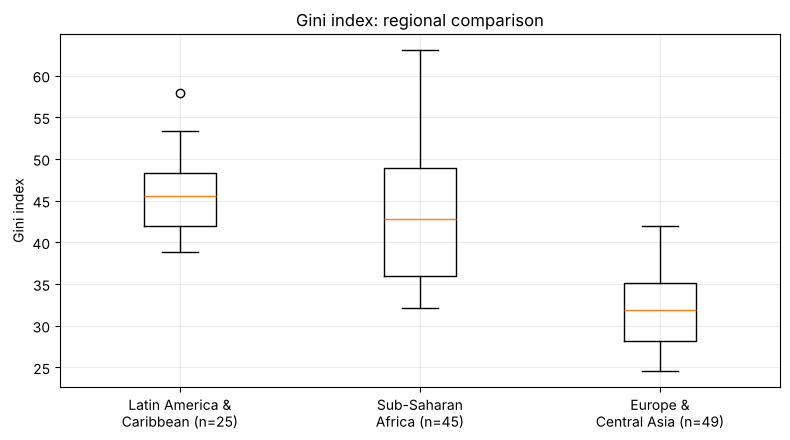

In [ ]:
lac = cross.loc[cross["Region"] == "Latin America & Caribbean", "Gini"].dropna().values
ssa_vals = cross.loc[cross["Region"] == "Sub-Saharan Africa", "Gini"].dropna().values
n1, n2 = len(lac), len(ssa_vals)
m1, m2 = lac.mean(), ssa_vals.mean()
v1, v2 = lac.var(ddof=1), ssa_vals.var(ddof=1)

print(pd.DataFrame({"Group": ["Latin America & Caribbean", "Sub-Saharan Africa"], "n": [n1, n2],
                    "Mean": [m1, m2], "SD": [np.sqrt(v1), np.sqrt(v2)]}).round(3).to_string(index=False))

# --- F-test for equality of variances ---
F = max(v1, v2) / min(v1, v2)
dfa, dfb = (n1 - 1, n2 - 1) if v1 >= v2 else (n2 - 1, n1 - 1)
p_F = min(1, 2 * stats.f.sf(F, dfa, dfb))
lev = stats.levene(lac, ssa_vals)
print(f"\nF-test for equal variances: F = {F:.3f}, p = {p_F:.4f};  Levene: p = {lev.pvalue:.4f}  "
      f"-> variances {'differ' if p_F < 0.05 else 'do not differ significantly'}")

# --- Pooled t-test (manual) ---
sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
t_pool = (m1 - m2) / np.sqrt(sp2 * (1 / n1 + 1 / n2)); df_pool = n1 + n2 - 2
p_pool = 2 * stats.t.sf(abs(t_pool), df_pool)

# --- Welch t-test (manual) ---
se_w = np.sqrt(v1 / n1 + v2 / n2)
t_w = (m1 - m2) / se_w
df_w = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
p_w = 2 * stats.t.sf(abs(t_w), df_w)

res = pd.DataFrame([
    {"Test": "Pooled (equal variances)", "t": t_pool, "df": df_pool, "p-value": p_pool},
    {"Test": "Welch (unequal variances)", "t": t_w, "df": df_w, "p-value": p_w},
])
display(res.round(4))

# SciPy cross-check
print("SciPy pooled :", stats.ttest_ind(lac, ssa_vals, equal_var=True))
print("SciPy Welch  :", stats.ttest_ind(lac, ssa_vals, equal_var=False))

cohen_d = (m1 - m2) / np.sqrt(sp2)
t_c = stats.t.ppf(0.975, df_w)
print(f"\nDifference in means = {m1 - m2:.3f}; 95% CI (Welch) = ({m1 - m2 - t_c*se_w:.2f}, {m1 - m2 + t_c*se_w:.2f})")
print(f"Cohen's d = {cohen_d:.3f}")
print("Decision (Welch, α = 0.05):", "Reject H0" if p_w < 0.05 else "Fail to reject H0")

log_test("t-test, two means – pooled (LAC vs SSA Gini)", "μ_LAC = μ_SSA", "μ_LAC ≠ μ_SSA", "t", t_pool, df_pool, p_pool)
log_test("t-test, two means – Welch (LAC vs SSA Gini)", "μ_LAC = μ_SSA", "μ_LAC ≠ μ_SSA", "t", t_w, round(df_w, 1), p_w)

# Second comparison with a clear difference: Europe & Central Asia vs Sub-Saharan Africa
eca = cross.loc[cross["Region"] == "Europe & Central Asia", "Gini"].dropna().values
t_e, p_e = stats.ttest_ind(eca, ssa_vals, equal_var=False)
dfe = (eca.var(ddof=1)/len(eca) + ssa_vals.var(ddof=1)/n2)**2 / ((eca.var(ddof=1)/len(eca))**2/(len(eca)-1) + (ssa_vals.var(ddof=1)/n2)**2/(n2-1))
print(f"\nEurope & Central Asia (mean {eca.mean():.1f}) vs Sub-Saharan Africa (mean {ssa_vals.mean():.1f}): Welch t = {t_e:.2f}, p = {p_e:.2e}")
log_test("t-test, two means – Welch (ECA vs SSA Gini)", "μ_ECA = μ_SSA", "μ_ECA ≠ μ_SSA", "t", t_e, round(dfe, 1), p_e)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([lac, ssa_vals, eca], vert=True)
ax.set_xticklabels([f"Latin America &\nCaribbean (n={n1})", f"Sub-Saharan\nAfrica (n={n2})", f"Europe &\nCentral Asia (n={len(eca)})"])
ax.set_ylabel("Gini index"); ax.set_title("Gini index: regional comparison")
plt.tight_layout(); plt.show()

**Significance of a correlation coefficient.** The $t$-distribution is also used to test whether a correlation is real or could arise by chance: under $H_0:\rho=0$, $t = \dfrac{r\sqrt{n-2}}{\sqrt{1-r^2}}\sim t_{(n-2)}$.

In [ ]:
# t-test for the significance of a correlation coefficient:  H0: ρ = 0,  t = r·sqrt(n−2)/sqrt(1−r²),  df = n−2
for a, b in [("Gini", "Lowest 20% share"), ("Gini", "Poverty $3.20")]:
    sub = cross[[a, b]].dropna()
    n = len(sub); r = sub[a].corr(sub[b])
    t_r = r * np.sqrt(n - 2) / np.sqrt(1 - r ** 2)
    p_r = 2 * stats.t.sf(abs(t_r), n - 2)
    print(f"{a} vs {b}: n = {n}, r = {r:.3f}, t = {t_r:.2f}, df = {n-2}, p = {p_r:.2e}  -> {'Reject H0 (ρ ≠ 0)' if p_r < 0.05 else 'Fail to reject H0'}")
    log_test(f"t-test, significance of Pearson r ({a} vs {b})", "ρ = 0", "ρ ≠ 0", "t", t_r, n - 2, p_r)

Gini vs Lowest 20% share: n = 163, r = -0.935, t = -33.47, df = 161, p = 2.03e-74  -> Reject H0 (ρ ≠ 0)
Gini vs Poverty $3.20: n = 164, r = 0.410, t = 5.72, df = 162, p = 5.10e-08  -> Reject H0 (ρ ≠ 0)


### 8.4 Chi-Square Test for Goodness of Fit

The χ² goodness-of-fit test checks whether observed category counts $O_i$ agree with the counts $E_i$ expected under a hypothesised distribution:

$$
\boxed{\chi^2 = \sum_{i=1}^{k}\frac{(O_i-E_i)^2}{E_i}}\ \sim\ \chi^2_{(\nu)},\qquad \nu = k - 1 - m
$$

where $k$ = number of categories and $m$ = number of parameters estimated from the data. The test is right-tailed (reject $H_0$ when $\chi^2$ is large) and requires every expected count $E_i \ge 5$ (approximately).

**(a) Equal-proportions test.** Are the countries equally likely to fall in the *Low*, *Moderate* and *High* inequality categories? $H_0: p_{\text{low}}=p_{\text{moderate}}=p_{\text{high}}=1/3$.

**(b) Normality test.** Is the Gini index of countries normally distributed? The data are split into $k=8$ **equal-probability** classes under $N(\bar{x}, s^2)$, so each class has the same expected count $E=N/8$; two parameters (mean and SD) are estimated, hence $\nu=k-1-2=5$. $H_0$: Gini follows a normal distribution.

,Category,Observed O,Expected E,(O−E)²/E
0,Low (Gini ≤ 30),24,54.667,17.203
1,Moderate (30 < Gini ≤ 40),77,54.667,9.124
2,High (Gini > 40),63,54.667,1.270


χ² = 27.598, df = 2, critical value (5%) = 5.991, p-value = 1.017e-06
Decision: Reject H0 | SciPy check: Power_divergenceResult(statistic=np.float64(27.597560975609756), pvalue=np.float64(1.0168708015028617e-06))


,Class,Observed,Expected (normal)
0,"(-inf, 29.2]",18,20.5
1,"(29.2, 32.9]",27,20.5
2,"(32.9, 35.7]",28,20.5
3,"(35.7, 38.3]",17,20.5
4,"(38.3, 40.8]",15,20.5
5,"(40.8, 43.6]",23,20.5
6,"(43.6, 47.4]",14,20.5
7,"(47.4, inf]",22,20.5


χ² = 9.659, df = 5, critical value (5%) = 11.070, p-value = 0.0855
Decision: Fail to reject H0 (normality is plausible)


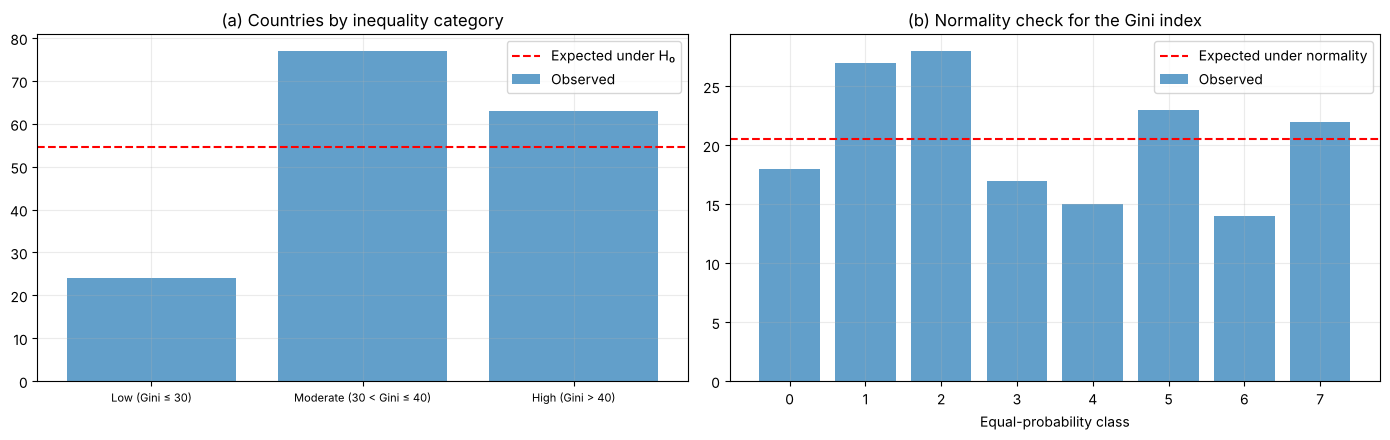

In [ ]:
# ---------- (a) equal proportions ----------
obs = cross["Inequality level"].value_counts().reindex(cross["Inequality level"].cat.categories)
N = obs.sum(); k = len(obs)
exp = np.full(k, N / k)
chi2_a = ((obs.values - exp) ** 2 / exp).sum()
df_a = k - 1
p_a = stats.chi2.sf(chi2_a, df_a)
crit_a = stats.chi2.ppf(0.95, df_a)

gof_table = pd.DataFrame({"Category": obs.index, "Observed O": obs.values, "Expected E": exp,
                          "(O−E)²/E": (obs.values - exp) ** 2 / exp})
display(gof_table.round(3))
print(f"χ² = {chi2_a:.3f}, df = {df_a}, critical value (5%) = {crit_a:.3f}, p-value = {p_a:.3e}")
print("Decision:", "Reject H0" if p_a < 0.05 else "Fail to reject H0", "| SciPy check:", stats.chisquare(obs.values))
log_test("χ² goodness of fit (equal inequality categories)", "all 3 categories equally likely", "not equally likely", "χ²", chi2_a, df_a, p_a)

# ---------- (b) normality ----------
kk = 8
mean_g, sd_g = gini_pop.mean(), gini_pop.std(ddof=1)
cuts = stats.norm.ppf(np.linspace(0, 1, kk + 1)[1:-1], mean_g, sd_g)      # equal-probability class boundaries
obs_n = np.bincount(np.searchsorted(cuts, gini_pop.values), minlength=kk)
exp_n = np.full(kk, len(gini_pop) / kk)
chi2_b = ((obs_n - exp_n) ** 2 / exp_n).sum()
df_b = kk - 1 - 2
p_b = stats.chi2.sf(chi2_b, df_b)
edges = np.r_[-np.inf, cuts, np.inf]
norm_table = pd.DataFrame({"Class": [f"({edges[i]:.1f}, {edges[i+1]:.1f}]" for i in range(kk)],
                           "Observed": obs_n, "Expected (normal)": exp_n})
display(norm_table.round(2))
print(f"χ² = {chi2_b:.3f}, df = {df_b}, critical value (5%) = {stats.chi2.ppf(0.95, df_b):.3f}, p-value = {p_b:.4f}")
print("Decision:", "Reject H0 (not normal)" if p_b < 0.05 else "Fail to reject H0 (normality is plausible)")
log_test("χ² goodness of fit (normality of Gini)", "Gini ~ Normal", "Gini not normal", "χ²", chi2_b, df_b, p_b)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(obs.index.astype(str), obs.values, alpha=0.7, label="Observed")
axes[0].axhline(N / k, color="red", linestyle="--", label="Expected under H₀")
axes[0].set_title("(a) Countries by inequality category"); axes[0].legend(); axes[0].tick_params(axis="x", labelsize=8)
axes[1].bar(range(kk), obs_n, alpha=0.7, label="Observed")
axes[1].axhline(len(gini_pop) / kk, color="red", linestyle="--", label="Expected under normality")
axes[1].set_xlabel("Equal-probability class"); axes[1].set_title("(b) Normality check for the Gini index"); axes[1].legend()
plt.tight_layout(); plt.show()

### 8.5 Chi-Square Test of Independence of Attributes

To test whether two categorical attributes are **independent**, arrange the counts in an $r\times c$ contingency table. Under $H_0$ (independence) the expected count in each cell is

$$
\boxed{E_{ij} = \frac{(\text{row total}_i)\times(\text{column total}_j)}{\text{grand total}}},\qquad
\chi^2=\sum_{i=1}^{r}\sum_{j=1}^{c}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},\qquad \nu=(r-1)(c-1)
$$

The strength of association is measured by **Cramér's V**: $V=\sqrt{\dfrac{\chi^2}{N\,\min(r-1,\,c-1)}}$ (0 = no association, 1 = perfect association). **Standardised residuals** $(O-E)/\sqrt{E}$ show which cells drive a significant result (|value| > 2 is notable).

**Problem.** Is a country's **inequality level** (Low / Moderate / High Gini) independent of its **World Bank income group**? $H_0$: the two attributes are independent; $H_1$: they are associated.

Observed contingency table:


Inequality level,Low (Gini ≤ 30),Moderate (30 < Gini ≤ 40),High (Gini > 40)
Income Group,,,
Low income,0,12,11
Lower middle income,4,24,26
Upper middle income,7,18,22
High income,13,23,3


Expected counts under independence:


Inequality level,Low (Gini ≤ 30),Moderate (30 < Gini ≤ 40),High (Gini > 40)
Income Group,,,
Low income,3.39,10.87,8.75
Lower middle income,7.95,25.51,20.54
Upper middle income,6.92,22.20,17.88
High income,5.74,18.42,14.83


Minimum expected count = 3.39; cells with expected count < 5: 1 of 12  (≥ 5 is the usual rule of thumb)

χ² = 29.087 (manual 29.087), df = 6, critical value (5%) = 12.592, p-value = 5.859e-05
Cramér's V = 0.299
Decision: Reject H0 (attributes are associated)

Robustness check on the merged 4×2 table: min expected = 8.75, χ² = 20.049, df = 3, p = 1.66e-04

Standardised residuals (|value| > 2 marks the cells that contribute most):


Inequality level,Low (Gini ≤ 30),Moderate (30 < Gini ≤ 40),High (Gini > 40)
Income Group,,,
Low income,-1.84,0.34,0.76
Lower middle income,-1.40,-0.30,1.20
Upper middle income,0.03,-0.89,0.98
High income,3.03,1.07,-3.07


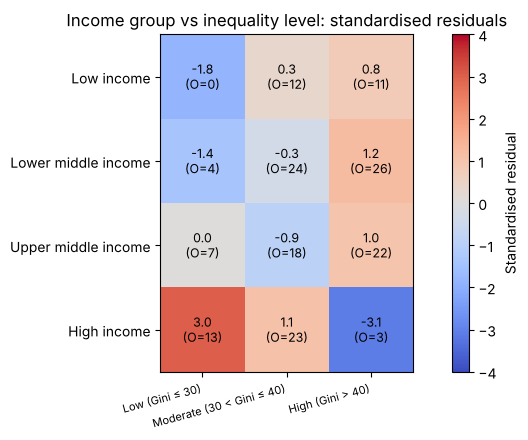

In [ ]:
order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
ct = pd.crosstab(cross["Income Group"], cross["Inequality level"]).reindex(order)
print("Observed contingency table:")
display(ct)

chi2_i, p_i, dof_i, expected = stats.chi2_contingency(ct, correction=False)
expected = pd.DataFrame(expected, index=ct.index, columns=ct.columns)
print("Expected counts under independence:")
display(expected.round(2))
n_small = int((expected.values < 5).sum())
print(f"Minimum expected count = {expected.values.min():.2f}; cells with expected count < 5: {n_small} of {expected.size}  (≥ 5 is the usual rule of thumb)")

# manual check of the formula
chi2_manual = (((ct - expected) ** 2) / expected).values.sum()
N = ct.values.sum()
cramers_v = np.sqrt(chi2_i / (N * (min(ct.shape) - 1)))
print(f"\nχ² = {chi2_i:.3f} (manual {chi2_manual:.3f}), df = {dof_i}, critical value (5%) = {stats.chi2.ppf(0.95, dof_i):.3f}, p-value = {p_i:.3e}")
print(f"Cramér's V = {cramers_v:.3f}")
print("Decision:", "Reject H0 (attributes are associated)" if p_i < 0.05 else "Fail to reject H0 (independence plausible)")
log_test("χ² independence (income group × inequality level)", "independent", "associated", "χ²", chi2_i, dof_i, p_i)

# Robustness check: merge "Low" and "Moderate" so that every expected count is comfortably large (4 x 2 table)
ct2 = pd.DataFrame({"Not high (Gini ≤ 40)": ct.iloc[:, 0] + ct.iloc[:, 1], "High (Gini > 40)": ct.iloc[:, 2]})
chi2_2, p_2, dof_2, exp_2 = stats.chi2_contingency(ct2, correction=False)
print(f"\nRobustness check on the merged 4×2 table: min expected = {exp_2.min():.2f}, χ² = {chi2_2:.3f}, df = {dof_2}, p = {p_2:.2e}")

resid = (ct - expected) / np.sqrt(expected)
print("\nStandardised residuals (|value| > 2 marks the cells that contribute most):")
display(resid.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(resid.values, cmap="coolwarm", vmin=-4, vmax=4)
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=15, ha="right", fontsize=8)
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{resid.values[i, j]:.1f}\n(O={ct.values[i, j]})", ha="center", va="center", fontsize=9)
ax.grid(False); fig.colorbar(im, label="Standardised residual")
ax.set_title("Income group vs inequality level: standardised residuals")
plt.tight_layout(); plt.show()

### 8.6 Choosing the Right Test (quick guide)

| Situation | Test used here |
|---|---|
| One mean, $\sigma$ known or large $n$ | Z-test (Section 7.5) |
| One proportion, large $n$ | Z-test for proportion (Section 7.6) |
| One mean, $\sigma$ unknown, small $n$ | One-sample t-test (Section 8.2) |
| Two independent means | Two-sample t-test (pooled / Welch) (Section 8.3) |
| Observed vs expected category counts | χ² goodness of fit (Section 8.4) |
| Association between two categorical variables | χ² test of independence (Section 8.5) |

### 8.7 Summary of All Hypothesis Tests

In [ ]:
summary_tests = pd.DataFrame(test_log)
summary_tests["p-value"] = summary_tests["p-value"].apply(lambda p: f"{p:.4f}" if p >= 0.0001 else f"{p:.2e}")
pd.set_option("display.max_colwidth", 60)
display(summary_tests)

,Test,H0,H1,Statistic,df,p-value,α,Decision
0,"Z-test, single mean (two-tailed)",μ(SSA Gini) = 40,μ ≠ 40,Z = 3.029,–,0.0025,0.05,Reject H0
1,"Z-test, single mean (right-tailed)",μ(SSA Gini) = 40,μ > 40,Z = 3.029,–,0.0012,0.05,Reject H0
2,"Z-test, single proportion (Sub-Saharan Africa)",p = 0.5,p ≠ 0.5,Z = 2.236,–,0.0253,0.05,Reject H0
3,"Z-test, single proportion (All countries)",p = 0.5,p ≠ 0.5,Z = -2.967,–,0.0030,0.05,Reject H0
4,"t-test, single mean (South Asia Gini)",μ = global mean Gini,μ ≠ global mean,t = -3.308,6,0.0162,0.05,Reject H0
5,"t-test, two means – pooled (LAC vs SSA Gini)",μ_LAC = μ_SSA,μ_LAC ≠ μ_SSA,t = 1.431,68,0.1569,0.05,Fail to reject H0
6,"t-test, two means – Welch (LAC vs SSA Gini)",μ_LAC = μ_SSA,μ_LAC ≠ μ_SSA,t = 1.643,67.6,0.1050,0.05,Fail to reject H0
7,"t-test, two means – Welch (ECA vs SSA Gini)",μ_ECA = μ_SSA,μ_ECA ≠ μ_SSA,t = -8.696,67.4,1.28e-12,0.05,Reject H0
8,"t-test, significance of Pearson r (Gini vs Lowest 20% sh...",ρ = 0,ρ ≠ 0,t = -33.472,161,2.03e-74,0.05,Reject H0
9,"t-test, significance of Pearson r (Gini vs Poverty $3.20)",ρ = 0,ρ ≠ 0,t = 5.717,162,5.10e-08,0.05,Reject H0


## 9. Main Results Summary (India)

In the supplied workbook, the available India observations include:

| Indicator | First available observation | Latest available observation |
|---|---:|---:|
| Poverty headcount ratio at $3.20 a day (2011 PPP) | 1977: 88.7% | 2011: 61.7% |
| Poverty headcount ratio at national poverty lines | 1993: 45.3% | 2011: 21.9% |
| Gini index (World Bank estimate) | 1983: 32.1 | 2011: 35.7 |
| Income share held by lowest 20% | 1983: 8.5% | 2011: 8.1% |

The values above are the first and latest available observations in this workbook for the selected India indicators.

## 10. Interpretation of Results

### 10.1 Poverty Trend

The poverty headcount ratio at $3.20 a day declined from **88.7% in 1977** to **61.7% in 2011**, a decrease of **27.0 percentage points**. The national poverty headcount ratio declined from **45.3% in 1993** to **21.9% in 2011**, a decrease of **23.4 percentage points**.

For a percentage indicator, the absolute change is expressed in percentage points.

**Percentage-Point Change:**

$$
\boxed{
\text{Percentage-point change}
=
\text{Latest percentage}
-
\text{First percentage}
}
$$

This is different from percentage change, which measures the relative change compared with the initial value.

**Percentage Change:**

$$
\boxed{
\%\text{ Change}
=
\frac{\text{Latest value}-\text{First value}}
{\text{First value}}
\times 100
}
$$

### 10.2 Income inequality

The Gini index increased from **32.1 in 1983** to **35.7 in 2011** in the available observations. A higher Gini value indicates greater income inequality. The income share held by the lowest 20% changed from **8.5% in 1983** to **8.1% in 2011**. These observations suggest that declining poverty ratios did not necessarily coincide with a reduction in measured income inequality.

### 10.3 Descriptive statistics and frequency distribution

The descriptive-statistics table summarises the centre and spread of each indicator. The mean gives the arithmetic average, the median gives the middle observation, the range shows the difference between the maximum and minimum, and the sample standard deviation measures dispersion around the mean.

The frequency tables group the available observations into value intervals. They help show where observations are concentrated. Since the number of observations is small and survey years are irregular, these tables should be interpreted as summaries of the recorded observations—not as annual distributions for every year.

### 10.4 Correlation results

The Pearson correlation matrix and scatter plots describe how the selected indicators move together in the years where both values are available. The displayed paired-year counts are important: a coefficient calculated from only a few survey years can change substantially if one observation changes.

A negative correlation between poverty and the Gini index, for example, would mean that the two indicators moved in opposite directions across the paired observations. It would **not** mean that poverty reduction caused inequality to rise or fall. Economic growth, employment, public policy, demographic changes, survey methods and other factors may influence these indicators.

### 10.5 Limitations

- The dataset contains many missing values; missing observations were excluded rather than replaced with zero.
- The selected indicators are available for different and irregular years.
- Correlation is based on pairwise overlapping years, so sample sizes differ between indicator pairs.
- The analysis is descriptive and exploratory. It does not identify causal effects.
- The $3.20/day poverty measure and national poverty-line measure use different poverty definitions and should not be treated as directly interchangeable.

### 10.6 Findings from Modules 1–3 (Visualization, Descriptive Statistics, Curve Fitting, Correlation, Regression)

- **Shape of the cross-country data.** The Gini index of the 164 countries is mildly right-skewed (skewness ≈ 0.65; mean 38.3 > median 37.1). The mode from the grouped-data formula (≈ 36.1) is close to the centre, and only three countries (South Africa, Namibia, Suriname) are outliers by the 1.5 × IQR rule. In contrast, the poverty headcount at $3.20/day is extremely spread out (from about 0% to over 90%).
- **India's position.** India's latest Gini (35.7) sits at roughly the 45th percentile of all countries — i.e. close to the middle of the world distribution and below the median of Sub-Saharan Africa and Latin America. However, India's $3.20/day poverty headcount (61.7%) lies at about the 80th percentile, i.e. higher than about four-fifths of the countries with data. India is therefore a **moderate-inequality but high-poverty** country by these indicators.
- **Regions differ.** The box plots show that Latin America & Caribbean and Sub-Saharan Africa have the highest and most dispersed Gini values, while Europe & Central Asia and South Asia have the lowest.
- **Least-squares curve fitting.** For India's poverty headcount a straight line fits well ($R^2 \approx 0.89$, falling by about 0.67 percentage points per year), and a parabola improves the fit ($R^2 \approx 0.93$, adjusted $R^2 \approx 0.90$ vs 0.86), reflecting a faster decline after 2004. For India's Gini index the parabola ($R^2 \approx 0.94$, adjusted 0.90) is clearly better than the line ($R^2 \approx 0.86$, adjusted 0.82) because inequality first stayed flat/dipped and then rose after the early 1990s (the curve's minimum is near the late 1980s). With only 6–7 points these are descriptive fits, not forecasts.
- **Correlation and regression.** Across countries the Gini index and the income share of the lowest 20% are very strongly negatively correlated (Pearson $r \approx -0.94$, Spearman $\rho \approx -0.94$): the regression line is $\hat{y} = 14.97 - 0.219\,\text{Gini}$ with $R^2 \approx 0.87$, so each extra Gini point is associated with a 0.22 percentage-point smaller bottom-20% share. For India's Gini the line predicts a share of about 7.2%, while the actual value is 8.1% — India's bottom quintile does slightly better than the typical country with the same Gini. Spearman's $\rho$ exceeds Pearson's $r$ for the poverty-based pairs (e.g. Gini vs poverty: $\rho \approx 0.56$ vs $r \approx 0.41$), which signals a monotonic but non-linear relationship. In India's own six survey years, Gini and the $3.20/day poverty are negatively related ($r \approx -0.92$, $\rho \approx -0.83$) — a statement about two trends moving in opposite directions over time, not about causation.

### 10.7 Findings from Modules 4–5 (Sampling, Estimation and Hypothesis Tests)

- **Sampling distribution and CLT.** Although the poverty headcount distribution is far from normal, the means of repeated samples become approximately normal as $n$ increases (skewness of $\bar{x}$ falls from 0.64 at $n=2$ to 0.05 at $n=100$), centre on the population mean (≈ 26.4), and their standard deviation matches $\sigma/\sqrt{n}$ (e.g. 2.93 vs 2.94 at $n=100$).
- **Confidence intervals.** The 95% CI for the mean Gini of all countries is (37.0, 39.5). For India's own six survey years the mean Gini is 33.65 with a 95% t-interval of (31.8, 35.5) — wide because $n$ is tiny. About 38% (CI: 31%–46%) of countries have high inequality (Gini > 40). The simulation of 100 intervals shows roughly 95 of them capture the true mean, which is what "95% confidence" means.
- **Z-tests.** Sub-Saharan Africa's mean Gini (43.6, $n=45$) is significantly higher than the benchmark 40 ($Z=3.03$; two-tailed $p=0.0025$, one-tailed $p=0.0012$). The proportion of Sub-Saharan countries with Gini > 40 (66.7%) is significantly different from 0.5 ($Z=2.24$, $p=0.025$), while for all countries the proportion (38.4%) is significantly *below* 0.5 ($Z=-2.97$, $p=0.003$).
- **Type-I and Type-II errors.** With $\alpha=0.05$ the simulated false-rejection rate was 4.9%, matching theory. For the Sub-Saharan sample the test has only about 52% power if the true mean were 42 (β ≈ 0.48), but about 96% power if it were 44 — a small effect is easy to miss even with $n=45$.
- **t-tests.** South Asian countries (n = 7) have a mean Gini of 34.4, significantly lower than the global mean of 38.3 ($t=-3.31$, df = 6, $p=0.016$). Latin America & Caribbean (mean 46.1) and Sub-Saharan Africa (43.6) are **not** significantly different (Welch $t=1.64$, $p=0.105$; the 95% CI for the difference, −0.5 to 5.6, includes 0), while Europe & Central Asia is far lower than Sub-Saharan Africa ($t=-8.7$, $p<0.0001$). The F-test shows unequal variances (Sub-Saharan Africa is more dispersed), so Welch's test is the appropriate choice.
- **Chi-square tests.** Countries are *not* equally spread over the Low/Moderate/High inequality categories ($\chi^2=27.6$, df = 2, $p<0.001$), but the Gini distribution is consistent with a normal distribution ($\chi^2=9.66$, df = 5, $p=0.086$). Inequality level and World Bank income group are **associated** ($\chi^2=29.1$, df = 6, $p<0.001$, Cramér's $V\approx0.30$, a moderate association): high-income countries have many more low-inequality countries and fewer high-inequality countries than expected under independence, which is where the large residuals lie. This result holds in the merged 4×2 table that satisfies the expected-count rule.

### 10.8 Limitations of the Inferential Analysis

- The cross-country observations are the *latest available* survey values and come from different years; countries are not a random sample from a larger population, so p-values describe differences among the countries in the workbook rather than generalise to a hypothetical wider set of countries.
- The Z-tests treat the all-country standard deviation as the known $\sigma$, and the benchmark values (Gini of 40, $p_0=0.5$) are conventions chosen for illustration.
- Several chi-square expected counts are below 5 in the 3-category contingency table; the merged-table check supports the same conclusion.
- Statistical significance does not measure practical importance and does not prove causation; effect sizes (Cohen's $d$, Cramér's $V$, $R^2$) are reported to put p-values in context.
- India's own time series has only 4–7 observations, so fitted curves, correlations and intervals based on it are fragile.

## 11. Conclusions

The analysis of the available World Bank observations for India shows a decline in both selected poverty headcount measures over their respective observation periods. At the same time, the available Gini-index observations increased, while the income share held by the lowest 20% changed only slightly.

Descriptive statistics, frequency distributions, trend charts, scatter plots and Pearson correlation provide complementary ways to summarise the dataset. Together, they show why poverty and inequality should be examined as related but distinct dimensions of economic well-being.

The findings must be interpreted with care because the data is sparse and does not cover every year. The results describe patterns in the available observations; they do not prove that one indicator caused a change in another. A future study could use more recent and more complete survey data to examine these relationships in greater depth.

### 11.1 Summary of Statistical Findings

Extending the descriptive analysis to the complete syllabus gives a consistent picture:

1. **Descriptive and graphical analysis (Modules 1–2)** shows that India has a middling Gini index (near the 45th percentile worldwide) but a high $3.20/day poverty headcount (near the 80th percentile). Regional box plots reveal that Latin America and Sub-Saharan Africa are the most unequal regions.
2. **Curve fitting, correlation and regression (Module 3)** show that India's poverty fell steadily while its Gini index followed a U-shaped path (a parabola fits much better than a line). Across countries, the Gini index explains about 87% of the variation in the bottom-20% income share, and Spearman's rank correlation confirms the same monotonic relationship.
3. **Sampling theory and confidence intervals (Module 4)** demonstrate the Central Limit Theorem and the effect of sample size on the standard error and margin of error; Z-tests show that Sub-Saharan Africa's inequality exceeds the Gini-40 benchmark, and the power analysis shows how Type-I and Type-II errors trade off.
4. **t-tests and chi-square tests (Module 5)** show that South Asia is significantly less unequal than the world average, that Latin America and Sub-Saharan Africa are not significantly different from each other, and that a country's inequality level is statistically associated with its income group.

Overall, the notebook shows that **reducing poverty and reducing inequality are different goals**: India's poverty indicators improved substantially while measured inequality rose slightly. The inferential results should be read with the data limitations in mind (sparse survey years, latest-available cross-section, convention-based benchmarks), and they describe association rather than cause.